<a href="https://colab.research.google.com/github/Carlos-Biologist/Automated-_Detection_and_Tracking_Pinnipeds_UAVs_YOLO26_-_BoT-SORT/blob/main/_YOLO26_Modelo_%C3%9Anico_REVIS_IL_%2B_REVIS_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **YOLO26m – modelo único (REVIS IL + REVIS ML)**

In [1]:
# Force unmounting of any previous Google Drive connection
!fusermount -u /content/drive 2>/dev/null || true

# Import and mount Google Drive
from google.colab import drive
import os
import shutil

try:
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    if os.path.exists('/content/drive'):
        shutil.rmtree('/content/drive')
    drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
# ======================================================
# 1. Install and import dependencies
# ======================================================
!pip install ultralytics -qq
!pip install scikit-learn -qq

import glob
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from sklearn.model_selection import StratifiedKFold
from ultralytics import YOLO
from ultralytics.utils.metrics import smooth   # Standard smoothing function employed by Ultralytics
import ultralytics

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
# ======================================================
# 2. Paths and global configuration
# ======================================================
ROOT = '/content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo'

# Splits (70/20/10) that ALREADY exist from the two single-area notebooks.
# Re-using them keeps the test sets identical to the ones evaluated before.
SPLITS_ORIGEM = {
    'IL': os.path.join(ROOT, 'Versão_2', 'split'),
    'ML': os.path.join(ROOT, 'REVIS_ML_Negativo', 'split'),
}

# New folders (nothing existing is overwritten)
UNI_BASE    = os.path.join(ROOT, 'Modelo_Unico_IL_ML')               # unified dataset + YAMLs
RESULTS_DIR = os.path.join(ROOT, 'Resultados_Modelo_Unico_IL_ML')    # all outputs

CLASS_NAMES = ['A_AUSTRALIS', 'O_FLAVESCENS']
EPOCHS = 50
IMGSZ = 640
BATCH = 8
K_FOLDS = 3
SEED = 42                       # SAME seed in every fold (identical head initialisation -> weights can be averaged)
EVAL_TREINO_POR_EPOCA = True    # Compute training mAP per epoch (increases runtime)
IOU_PRED = 0.6
RETOMAR = True                  # Skip folds whose training already finished (results.csv complete)

# Quick smoke test of the whole pipeline (1 epoch/fold, no per-epoch training mAP).
# Set to False for the real run.
MODO_TESTE_RAPIDO = False
if MODO_TESTE_RAPIDO:
    EPOCHS, EVAL_TREINO_POR_EPOCA, RETOMAR = 1, False, False
    RESULTS_DIR = RESULTS_DIR + '_TESTE_RAPIDO'

for area, p in SPLITS_ORIGEM.items():
    for s in ['train', 'val', 'test']:
        assert os.path.isdir(os.path.join(p, s, 'images')), f"❌ Missing {area} split folder: {os.path.join(p, s, 'images')}"

for d in [UNI_BASE, RESULTS_DIR]:
    if d == UNI_BASE and os.path.exists(d):
        shutil.rmtree(d)            # unified dataset is rebuilt from scratch on every run
    os.makedirs(d, exist_ok=True)

print("📁 Paths OK")
print(f"   Unified dataset : {UNI_BASE}")
print(f"   Results         : {RESULTS_DIR}")

📁 Paths OK
   Unified dataset : /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML
   Results         : /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML


In [ ]:
# ======================================================
# 3. Read the existing splits of both areas
# Class 0 = A_AUSTRALIS, Class 1 = O_FLAVESCENS (final schema of both notebooks)
# Negative images = empty label files
# ======================================================
EXTS = ('.jpg', '.jpeg', '.png')

def listar_split(split_path, area, subset):
    img_dir = os.path.join(split_path, subset, 'images')
    lbl_dir = os.path.join(split_path, subset, 'labels')
    rows = []
    for f in sorted(os.listdir(img_dir)):
        if not f.lower().endswith(EXTS):
            continue
        stem = os.path.splitext(f)[0]
        lbl = os.path.join(lbl_dir, stem + '.txt')
        if not os.path.exists(lbl):
            print(f"⚠️ {area}/{subset}: label not found for {f} (treated as negative)")
        au = fl = 0
        if os.path.exists(lbl):
            with open(lbl, 'r') as fh:
                for line in fh:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cid = int(parts[0])
                    if cid == 0:
                        au += 1
                    elif cid == 1:
                        fl += 1
                    else:
                        raise ValueError(f"⚠️ Unexpected class ID {cid} in {lbl}")
        rows.append({
            'area': area, 'subset': subset, 'image': f,
            'src_img': os.path.join(img_dir, f), 'src_lbl': lbl,
            'new_name': f"{area}__{f}",                 # prefix avoids file-name collisions between areas
            'australis': au, 'flavescens': fl,
        })
    return rows

rows = []
for area, p in SPLITS_ORIGEM.items():
    for subset in ['train', 'val', 'test']:
        rows += listar_split(p, area, subset)

all_df = pd.DataFrame(rows)
assert all_df['new_name'].is_unique, "Duplicated image names after prefixing"

# Dominant class per image (ties -> A. australis, same rule as idxmax in the original notebooks)
all_df['n_boxes'] = all_df['australis'] + all_df['flavescens']
all_df['dominant_class_id'] = np.where(all_df['n_boxes'] == 0, -1,
                                       np.where(all_df['australis'] >= all_df['flavescens'], 0, 1))
all_df['stratum'] = all_df['area'] + '_' + all_df['dominant_class_id'].map({-1: 'NEG', 0: 'A', 1: 'O'})

pool_df = all_df[all_df['subset'].isin(['train', 'val'])].reset_index(drop=True)   # train + val merged
test_df = all_df[all_df['subset'] == 'test'].reset_index(drop=True)

print("📊 Images per area and original subset:")
print(pd.crosstab(all_df['area'], all_df['subset']))
print(f"\n🧩 Pool (train+val of both areas): {len(pool_df)} images")
print(f"🧪 Independent test sets        : IL = {(test_df.area=='IL').sum()} | ML = {(test_df.area=='ML').sum()} | total = {len(test_df)}")

📊 Images per area and original subset:
subset  test  train  val
area                    
IL        76    526  150
ML        74    512  147

🧩 Pool (train+val of both areas): 1335 images
🧪 Independent test sets        : IL = 76 | ML = 74 | total = 150


In [ ]:
# ======================================================
# 4. Build the unified dataset (copies with area prefix)
#    pool/            -> train+val of IL and ML
#    test_IL/, test_ML/ -> original test sets (kept apart so each can be evaluated separately)
# ======================================================
def copiar(df_, destino):
    os.makedirs(os.path.join(destino, 'images'), exist_ok=True)
    os.makedirs(os.path.join(destino, 'labels'), exist_ok=True)
    for _, r in df_.iterrows():
        shutil.copy(r['src_img'], os.path.join(destino, 'images', r['new_name']))
        lbl_dst = os.path.join(destino, 'labels', os.path.splitext(r['new_name'])[0] + '.txt')
        if os.path.exists(r['src_lbl']):
            shutil.copy(r['src_lbl'], lbl_dst)
        else:
            open(lbl_dst, 'w').close()

POOL_DIR    = os.path.join(UNI_BASE, 'pool')
TEST_DIRS   = {a: os.path.join(UNI_BASE, f'test_{a}') for a in ['IL', 'ML']}

copiar(pool_df, POOL_DIR)
for a, d in TEST_DIRS.items():
    copiar(test_df[test_df['area'] == a], d)

n_pool_files = len(os.listdir(os.path.join(POOL_DIR, 'images')))
assert n_pool_files == len(pool_df), "Pool image count mismatch"
for a, d in TEST_DIRS.items():
    assert len(os.listdir(os.path.join(d, 'images'))) == (test_df['area'] == a).sum(), f"Test {a} count mismatch"

print("✅ Unified dataset created")
print(f"   pool: {n_pool_files} images | test_IL: {len(os.listdir(os.path.join(TEST_DIRS['IL'],'images')))} | test_ML: {len(os.listdir(os.path.join(TEST_DIRS['ML'],'images')))}")

✅ Unified dataset created
   pool: 1335 images | test_IL: 76 | test_ML: 74


In [ ]:
# ======================================================
# 5. Stratified K-fold (K = 3) on the pool + dataset YAMLs
#    Stratum = area x (dominant species | negative), so every fold keeps
#    the area proportions, the species proportions and the negative images balanced.
# ======================================================
strata = pool_df['stratum'].copy()
raros = strata.map(strata.value_counts()) < K_FOLDS
if raros.any():
    print(f"⚠️ Strata with fewer than {K_FOLDS} images merged into 'RARO': {sorted(strata[raros].unique())}")
    strata[raros] = 'RARO'

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
pool_df['fold'] = -1
for k, (_, va_idx) in enumerate(skf.split(pool_df, strata), start=1):
    pool_df.loc[va_idx, 'fold'] = k          # fold k = validation fold of round k
assert (pool_df['fold'] > 0).all()

FOLDS_DIR = os.path.join(UNI_BASE, 'folds')
os.makedirs(FOLDS_DIR, exist_ok=True)

def caminho_pool(nome):
    return os.path.join(POOL_DIR, 'images', nome)

def escrever_yaml(path, train, val, test=None):
    d = {'path': UNI_BASE, 'train': train, 'val': val}
    if test is not None:
        d['test'] = test
    d['nc'] = len(CLASS_NAMES)
    d['names'] = {i: n for i, n in enumerate(CLASS_NAMES)}
    with open(path, 'w') as f:
        yaml.safe_dump(d, f, sort_keys=False, allow_unicode=True)
    return path

TEST_IMG_DIRS = {a: os.path.join(d, 'images') for a, d in TEST_DIRS.items()}
YAML_FOLD, YAML_FOLD_TRAIN_EVAL = {}, {}

for k in range(1, K_FOLDS + 1):
    tr = pool_df[pool_df['fold'] != k]
    va = pool_df[pool_df['fold'] == k]
    f_tr = os.path.join(FOLDS_DIR, f'fold{k}_train.txt')
    f_va = os.path.join(FOLDS_DIR, f'fold{k}_val.txt')
    with open(f_tr, 'w') as f:
        f.write('\n'.join(caminho_pool(n) for n in tr['new_name']) + '\n')
    with open(f_va, 'w') as f:
        f.write('\n'.join(caminho_pool(n) for n in va['new_name']) + '\n')
    YAML_FOLD[k] = escrever_yaml(os.path.join(FOLDS_DIR, f'fold{k}.yaml'), f_tr, f_va)
    # Auxiliary YAML: "validation" = training split, to compute training mAP per epoch
    YAML_FOLD_TRAIN_EVAL[k] = escrever_yaml(os.path.join(FOLDS_DIR, f'fold{k}_train_eval.yaml'), f_tr, f_tr)

# YAMLs for the three test evaluations (train/val keys are required by Ultralytics but unused with split='test')
dummy = os.path.join(POOL_DIR, 'images')
YAML_TESTE = {
    'teste_geral': escrever_yaml(os.path.join(UNI_BASE, 'test_geral.yaml'), dummy, dummy,
                                 test=[TEST_IMG_DIRS['IL'], TEST_IMG_DIRS['ML']]),
    'teste_IL':    escrever_yaml(os.path.join(UNI_BASE, 'test_IL.yaml'), dummy, dummy, test=TEST_IMG_DIRS['IL']),
    'teste_ML':    escrever_yaml(os.path.join(UNI_BASE, 'test_ML.yaml'), dummy, dummy, test=TEST_IMG_DIRS['ML']),
}

pool_df[['image', 'area', 'subset', 'new_name', 'australis', 'flavescens', 'stratum', 'fold']].to_csv(
    os.path.join(RESULTS_DIR, 'pool_folds.csv'), index=False, encoding='utf-8-sig')

print("🔀 Images per fold (validation fold of each round):")
print(pd.crosstab(pool_df['fold'], pool_df['stratum']))
print(f"\n✅ YAMLs created in {FOLDS_DIR} and {UNI_BASE}")

🔀 Images per fold (validation fold of each round):
stratum  IL_A  IL_NEG  IL_O  ML_A  ML_NEG  ML_O
fold                                           
1          63      16   147    13      13   193
2          63      15   147    13      14   193
3          63      16   146    13      14   193

✅ YAMLs created in /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/folds and /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML



📊 Summary of images and bounding boxes:
                     Set  Total images  Positive images  Negative images  A. australis (class 0)  O. flavescens (class 1)
   Pool (train+val) - IL           676              629               47                    7575                    11530
   Pool (train+val) - ML           659              618               41                     179                     1623
Pool (train+val) - Total          1335             1247               88                    7754                    13153
       Fold 1 - training           890              831               59                    5208                     8794
     Fold 1 - validation           445              416               29                    2546                     4359
       Fold 2 - training           890              831               59                    5101                     8925
     Fold 2 - validation           445              416               29                    2653         

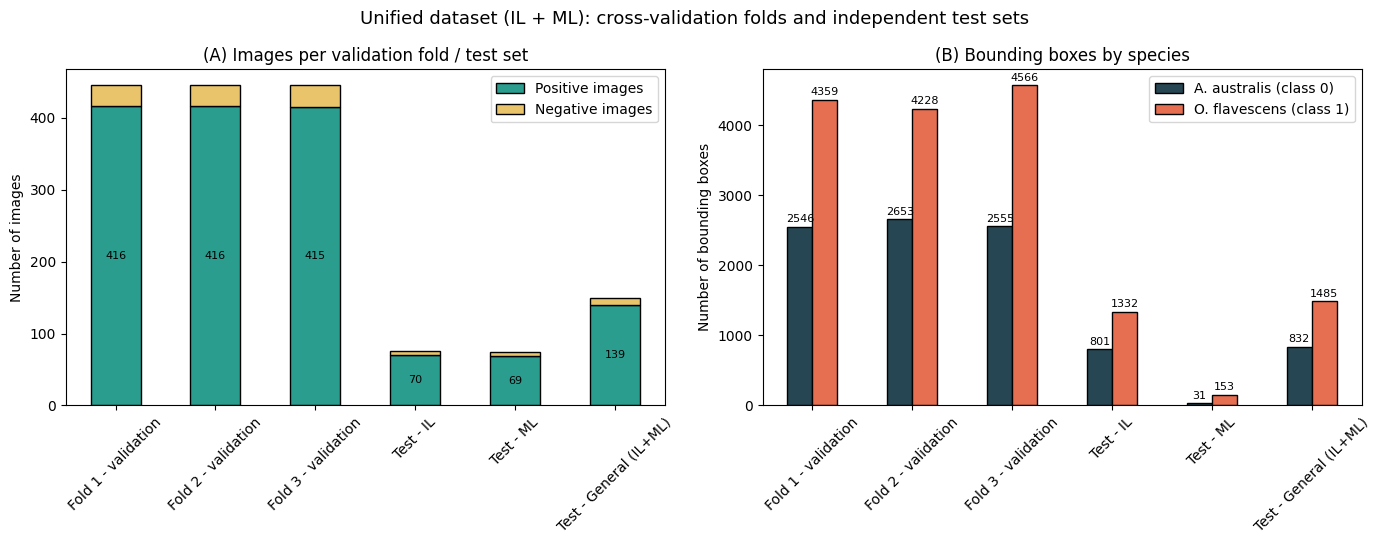

In [ ]:
# ======================================================
# 6. Quantify images and bounding boxes per set
# ======================================================
def resumo(nome, d):
    return {
        'Set': nome,
        'Total images': len(d),
        'Positive images': int((d['n_boxes'] > 0).sum()),
        'Negative images': int((d['n_boxes'] == 0).sum()),
        'A. australis (class 0)': int(d['australis'].sum()),
        'O. flavescens (class 1)': int(d['flavescens'].sum()),
    }

pool_df['n_boxes'] = pool_df['australis'] + pool_df['flavescens']
linhas = [resumo('Pool (train+val) - IL', pool_df[pool_df.area == 'IL']),
          resumo('Pool (train+val) - ML', pool_df[pool_df.area == 'ML']),
          resumo('Pool (train+val) - Total', pool_df)]
for k in range(1, K_FOLDS + 1):
    linhas.append(resumo(f'Fold {k} - training', pool_df[pool_df.fold != k]))
    linhas.append(resumo(f'Fold {k} - validation', pool_df[pool_df.fold == k]))
linhas += [resumo('Test - IL', test_df[test_df.area == 'IL']),
           resumo('Test - ML', test_df[test_df.area == 'ML']),
           resumo('Test - General (IL+ML)', test_df)]

df_counts = pd.DataFrame(linhas)
df_counts.to_csv(os.path.join(RESULTS_DIR, 'dataset_summary.csv'), index=False, encoding='utf-8-sig')
print("\n📊 Summary of images and bounding boxes:")
print(df_counts.to_string(index=False))

# Plot: validation folds and test sets
plot_df = df_counts[df_counts['Set'].str.contains('validation|Test')].set_index('Set')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_df[['Positive images', 'Negative images']].plot(kind='bar', stacked=True, ax=axes[0],
                                                     color=['#2a9d8f', '#e9c46a'], edgecolor='black')
axes[0].set_title('(A) Images per validation fold / test set')
axes[0].set_ylabel('Number of images'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)
axes[0].bar_label(axes[0].containers[0], label_type='center', fontsize=8)

plot_df[['A. australis (class 0)', 'O. flavescens (class 1)']].plot(kind='bar', ax=axes[1],
                                                                    color=['#264653', '#e76f51'], edgecolor='black')
axes[1].set_title('(B) Bounding boxes by species')
axes[1].set_ylabel('Number of bounding boxes'); axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=45)
for c in axes[1].containers:
    axes[1].bar_label(c, fontsize=8, padding=2)

plt.suptitle('Unified dataset (IL + ML): cross-validation folds and independent test sets', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'dataset_split_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ======================================================
# 7. Training: one YOLO26m per fold (3 models), same hyperparameters as the single-area notebooks
# ======================================================
FOLDS_RES = os.path.join(RESULTS_DIR, 'folds')
os.makedirs(FOLDS_RES, exist_ok=True)

run_dirs, best_pts = {}, {}

for k in range(1, K_FOLDS + 1):
    nome = f'fold{k}_treino'
    run_dir_k = os.path.join(FOLDS_RES, nome)
    best_k = os.path.join(run_dir_k, 'weights', 'best.pt')
    res_csv = os.path.join(run_dir_k, 'results.csv')

    concluido = False
    if RETOMAR and os.path.exists(best_k) and os.path.exists(res_csv):
        concluido = len(pd.read_csv(res_csv)) >= EPOCHS

    if concluido:
        print(f"⏭️  Fold {k}: training already completed, skipping -> {run_dir_k}")
    else:
        print(f"\n🚀 Fold {k}/{K_FOLDS}: training (Ultralytics {ultralytics.__version__})...")
        model = YOLO('yolo26m.pt')
        model.train(
            data=YAML_FOLD[k],
            epochs=EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH,
            seed=SEED,
            deterministic=True,
            project=FOLDS_RES,
            name=nome,
            exist_ok=True,
            save_period=1 if EVAL_TREINO_POR_EPOCA else -1,
            plots=True
        )
        run_dir_k = str(model.trainer.save_dir)
        best_k = os.path.join(run_dir_k, 'weights', 'best.pt')
        del model
        torch.cuda.empty_cache()

    run_dirs[k], best_pts[k] = run_dir_k, best_k
    print(f"✅ Fold {k}: {best_k}")


🚀 Fold 1/3: training (Ultralytics 8.4.215)...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/folds/fold1.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train,

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.0 ms, read: 70.0±7.1 MB/s, size: 73.3 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels... 890 images, 59 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 890/890 194.4it/s 4.6s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 1.6it/s 34.0s
                   all        890      14002       0.44       0.24      0.238     0.0845
Speed: 1.0ms preprocess, 32.7ms inference, 0.0ms loss, 2.0ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused):

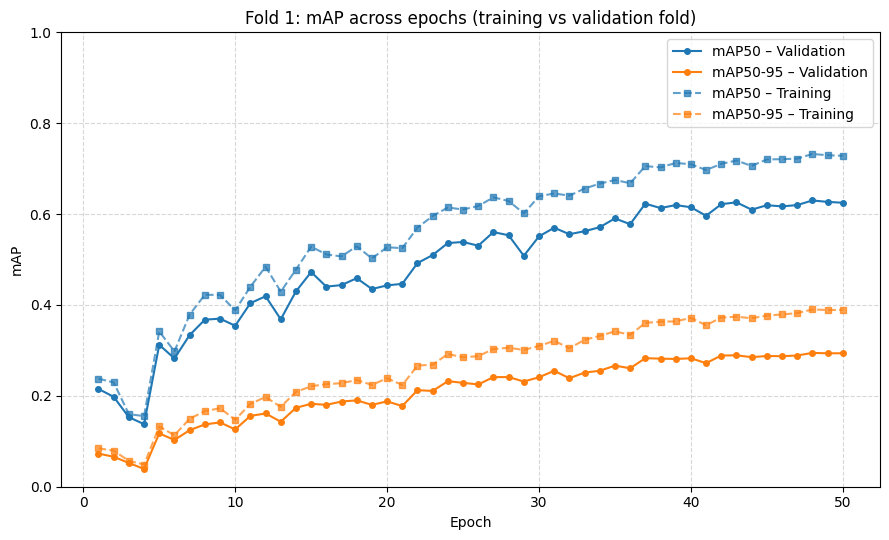

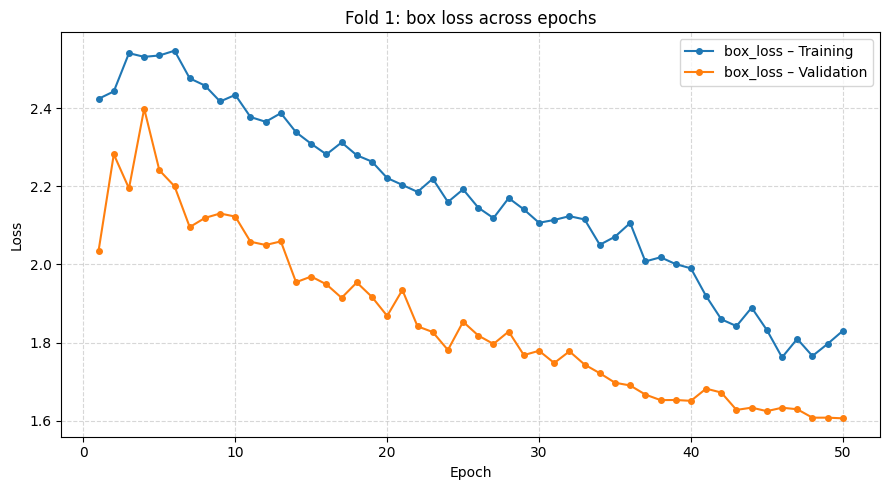

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 88.3±19.1 MB/s, size: 94.5 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels... 890 images, 59 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 890/890 204.2it/s 4.4s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 1.7it/s 33.6s
                   all        890      14026      0.446      0.173      0.152     0.0531
Speed: 1.1ms preprocess, 31.9ms inference, 0.0ms loss, 2.2ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused)

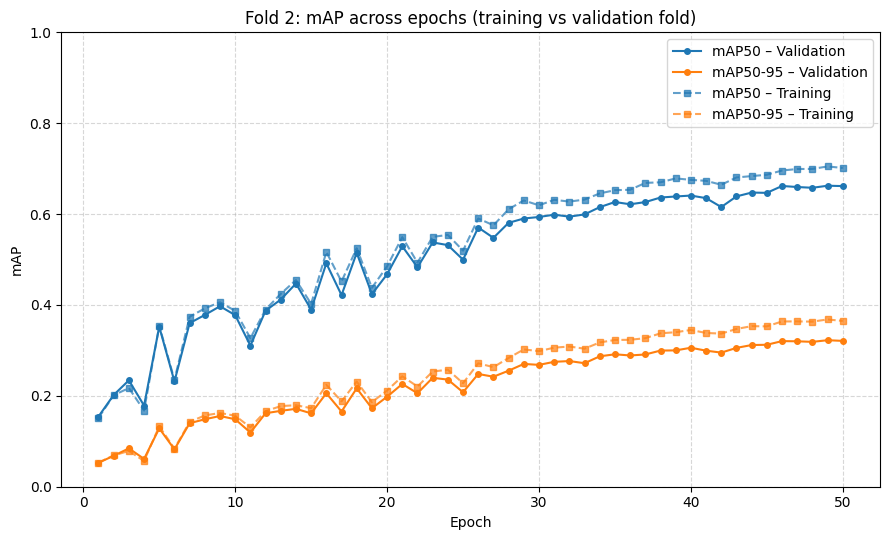

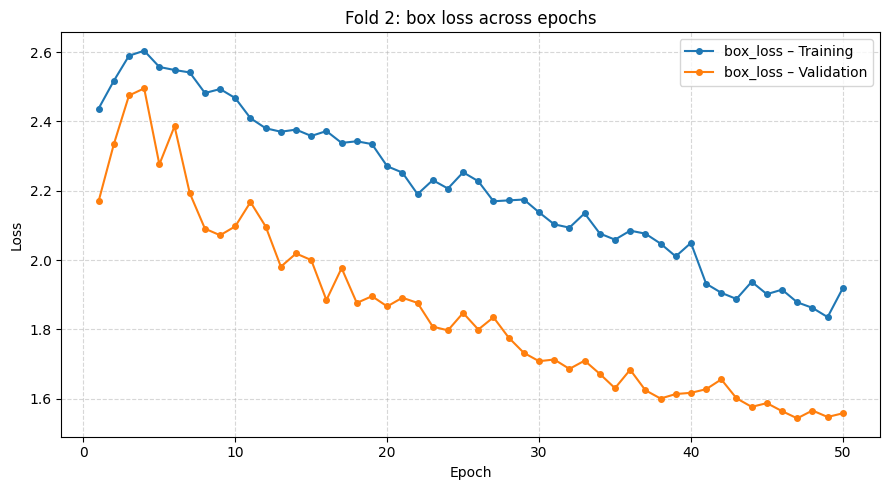

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.0 ms, read: 71.7±20.2 MB/s, size: 80.8 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels... 890 images, 58 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 890/890 195.2it/s 4.6s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 1.7it/s 33.7s
                   all        890      13786       0.26      0.273      0.165      0.055
Speed: 1.2ms preprocess, 32.0ms inference, 0.0ms loss, 2.0ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused)

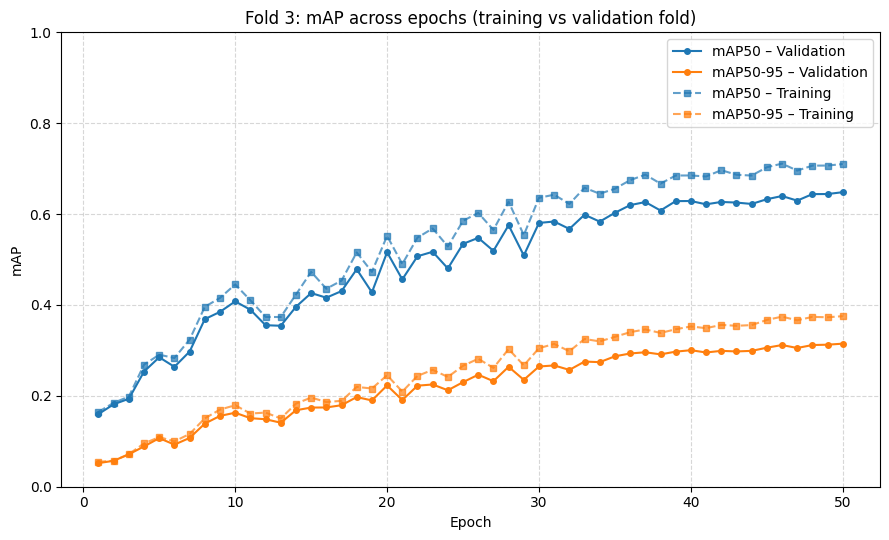

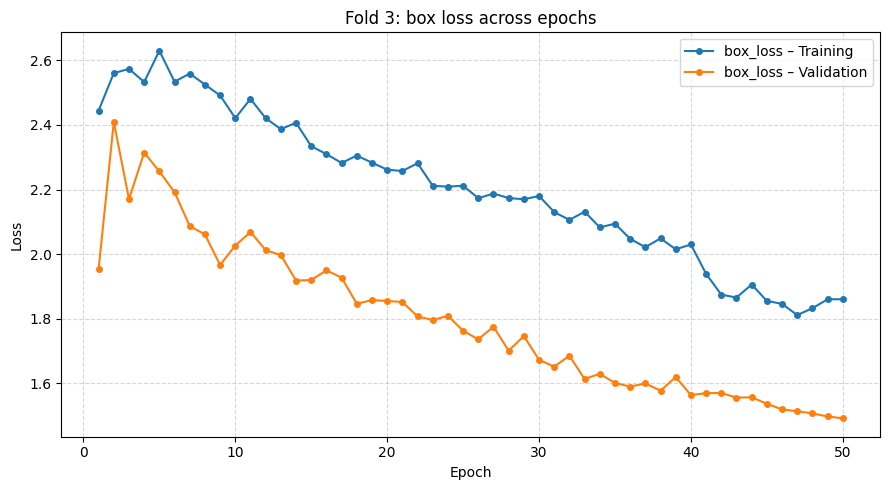

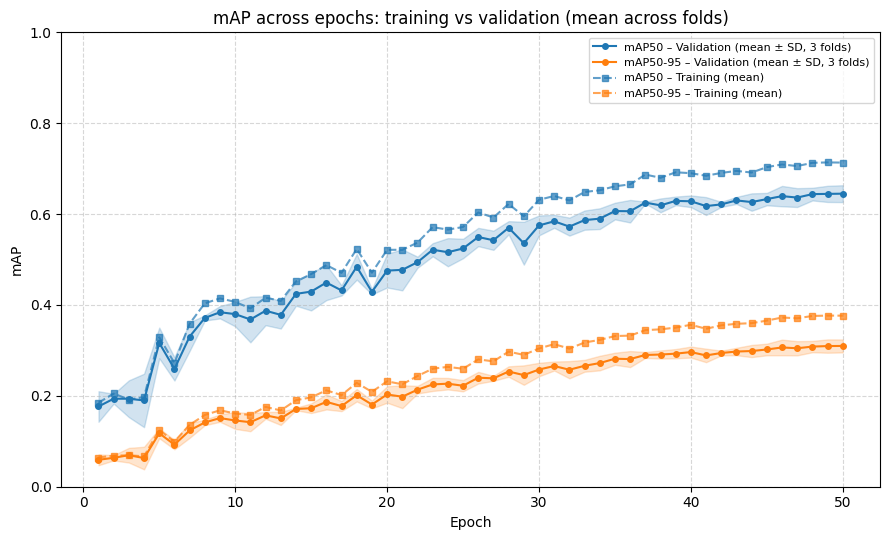

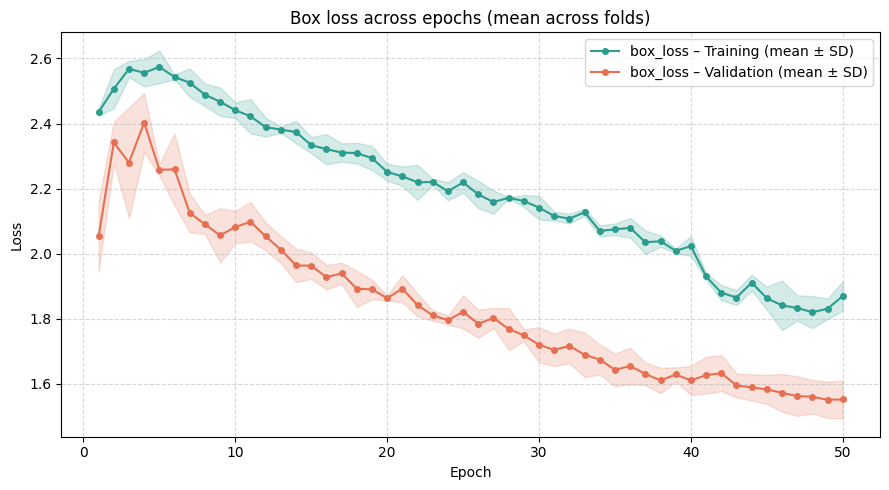

In [ ]:
# ======================================================
# 8. Training vs validation curves per epoch (each fold + mean ± SD across folds)
# ======================================================
res_folds = {}

for k in range(1, K_FOLDS + 1):
    run_dir_k = run_dirs[k]
    out_k = os.path.join(RESULTS_DIR, f'fold{k}')
    os.makedirs(out_k, exist_ok=True)

    res = pd.read_csv(os.path.join(run_dir_k, 'results.csv'))
    res.columns = res.columns.str.strip()
    epochs = res['epoch'].astype(int).values

    # Training mAP per epoch (evaluates each checkpoint on the fold training set)
    csv_k = os.path.join(out_k, 'metrics_per_epoch.csv')
    if EVAL_TREINO_POR_EPOCA:
        ckpts = sorted(
            glob.glob(os.path.join(run_dir_k, 'weights', 'epoch*.pt')),
            key=lambda p: int(re.findall(r'epoch(\d+)\.pt', p)[0])
        )
        if not ckpts and os.path.exists(csv_k):
            print(f"ℹ️ Fold {k}: epoch checkpoints already removed; re-using {csv_k}")
            res = pd.read_csv(csv_k)
        train_map50, train_map5095 = [], []
        for p in ckpts:
            m = YOLO(p).val(data=YAML_FOLD_TRAIN_EVAL[k], split='val', imgsz=IMGSZ, plots=False,
                            verbose=False, project=out_k, name='tmp_eval', exist_ok=True)
            train_map50.append(m.box.map50)
            train_map5095.append(m.box.map)
        n = min(len(ckpts), len(res))
        if n > 0:
            res.loc[:n - 1, 'train_mAP50'] = train_map50[:n]
            res.loc[:n - 1, 'train_mAP50-95'] = train_map5095[:n]
        for p in ckpts:
            os.remove(p)                       # free Google Drive space
        shutil.rmtree(os.path.join(out_k, 'tmp_eval'), ignore_errors=True)

    res.to_csv(os.path.join(out_k, 'metrics_per_epoch.csv'), index=False)
    res_folds[k] = res

    # mAP curves
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.plot(epochs, res['metrics/mAP50(B)'], '-o', ms=4, color='#1f77b4', label='mAP50 – Validation')
    ax.plot(epochs, res['metrics/mAP50-95(B)'], '-o', ms=4, color='#ff7f0e', label='mAP50-95 – Validation')
    if EVAL_TREINO_POR_EPOCA and 'train_mAP50' in res:
        ax.plot(epochs, res['train_mAP50'], '--s', ms=4, color='#1f77b4', alpha=0.7, label='mAP50 – Training')
        ax.plot(epochs, res['train_mAP50-95'], '--s', ms=4, color='#ff7f0e', alpha=0.7, label='mAP50-95 – Training')
    ax.set_xlabel('Epoch'); ax.set_ylabel('mAP'); ax.set_ylim(0, 1)
    ax.set_title(f'Fold {k}: mAP across epochs (training vs validation fold)')
    ax.grid(linestyle='--', alpha=0.5); ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(out_k, 'mAP_curve_per_epoch.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # Loss curves
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(epochs, res['train/box_loss'], '-o', ms=4, label='box_loss – Training')
    ax.plot(epochs, res['val/box_loss'], '-o', ms=4, label='box_loss – Validation')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title(f'Fold {k}: box loss across epochs')
    ax.grid(linestyle='--', alpha=0.5); ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(out_k, 'loss_curve_per_epoch.png'), dpi=300, bbox_inches='tight')
    plt.show()

# Mean ± SD across folds
n_ep = min(len(r) for r in res_folds.values())
ep = np.arange(n_ep)

def media_dp(col):
    arr = np.vstack([res_folds[k][col].values[:n_ep] for k in res_folds])
    return arr.mean(0), arr.std(0, ddof=1) if arr.shape[0] > 1 else np.zeros(n_ep)

fig, ax = plt.subplots(figsize=(9, 5.5))
for col, cor, lab in [('metrics/mAP50(B)', '#1f77b4', 'mAP50'), ('metrics/mAP50-95(B)', '#ff7f0e', 'mAP50-95')]:
    mu, sd = media_dp(col)
    ax.plot(ep + 1, mu, '-o', ms=4, color=cor, label=f'{lab} – Validation (mean ± SD, {K_FOLDS} folds)')
    ax.fill_between(ep + 1, mu - sd, mu + sd, color=cor, alpha=0.2)
if EVAL_TREINO_POR_EPOCA and all('train_mAP50' in r for r in res_folds.values()):
    for col, cor, lab in [('train_mAP50', '#1f77b4', 'mAP50'), ('train_mAP50-95', '#ff7f0e', 'mAP50-95')]:
        mu, sd = media_dp(col)
        ax.plot(ep + 1, mu, '--s', ms=4, color=cor, alpha=0.7, label=f'{lab} – Training (mean)')
ax.set_xlabel('Epoch'); ax.set_ylabel('mAP'); ax.set_ylim(0, 1)
ax.set_title('mAP across epochs: training vs validation (mean across folds)')
ax.grid(linestyle='--', alpha=0.5); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'mAP_curve_per_epoch.png'), dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for col, cor, lab in [('train/box_loss', '#2a9d8f', 'Training'), ('val/box_loss', '#e76f51', 'Validation')]:
    mu, sd = media_dp(col)
    ax.plot(ep + 1, mu, '-o', ms=4, color=cor, label=f'box_loss – {lab} (mean ± SD)')
    ax.fill_between(ep + 1, mu - sd, mu + sd, color=cor, alpha=0.2)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.set_title('Box loss across epochs (mean across folds)')
ax.grid(linestyle='--', alpha=0.5); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'loss_curve_per_epoch.png'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ======================================================
# 9. Cross-validation performance (out-of-fold) and confidence threshold
#    Each fold model is evaluated on the fold it did NOT train on.
#    Threshold per fold = confidence that maximises the macro F1-score on that held-out fold;
#    the final threshold is the mean of the K thresholds (no test data involved).
# ======================================================
def tabela_metricas(b, conf):
    """Per-class and macro-average metrics at a given confidence threshold (same logic as the single-area notebooks)."""
    idx = int(np.abs(b.px - conf).argmin())
    rows = []
    for k, c in enumerate(b.ap_class_index):
        rows.append({
            'Class': CLASS_NAMES[c],
            'mAP50': b.ap50[k],
            'mAP50-95': b.ap[k],
            'Precision': b.p_curve[k, idx],
            'Recall': b.r_curve[k, idx],
            'F1-Score': b.f1_curve[k, idx],
        })
    rows.insert(0, {
        'Class': 'all',
        'mAP50': b.map50,
        'mAP50-95': b.map,
        'Precision': np.mean([r['Precision'] for r in rows]),
        'Recall': np.mean([r['Recall'] for r in rows]),
        'F1-Score': np.mean([r['F1-Score'] for r in rows]),
    })
    return pd.DataFrame(rows)

cv_rows, confs_fold = [], {}
for k in range(1, K_FOLDS + 1):
    mv = YOLO(best_pts[k]).val(data=YAML_FOLD[k], split='val', imgsz=IMGSZ, plots=False, verbose=False,
                               project=RESULTS_DIR, name='tmp_val', exist_ok=True)
    conf_k = float(mv.box.px[smooth(mv.box.f1_curve.mean(0), 0.1).argmax()])
    confs_fold[k] = conf_k
    t = tabela_metricas(mv.box, conf_k)
    for _, r in t.iterrows():
        cv_rows.append({'Fold': k, 'conf_threshold': conf_k, **r.to_dict()})
shutil.rmtree(os.path.join(RESULTS_DIR, 'tmp_val'), ignore_errors=True)

cv_df = pd.DataFrame(cv_rows)
metr = ['mAP50', 'mAP50-95', 'Precision', 'Recall', 'F1-Score']
resumo_cv = (cv_df.groupby('Class')[metr].agg(['mean', 'std']).round(4))
resumo_cv.columns = [f'{a}_{b}' for a, b in resumo_cv.columns]
resumo_cv = resumo_cv.reset_index()

cv_df.to_csv(os.path.join(RESULTS_DIR, 'cv_metricas_por_fold.csv'), index=False, encoding='utf-8-sig')
resumo_cv.to_csv(os.path.join(RESULTS_DIR, 'cv_metricas_media_dp.csv'), index=False, encoding='utf-8-sig')

best_conf = float(np.mean(list(confs_fold.values())))
print("🎯 Confidence thresholds per fold:", {k: round(v, 3) for k, v in confs_fold.items()})
print(f"🎯 Final confidence threshold (mean of folds): {best_conf:.3f}")
print("\n📈 Cross-validation (out-of-fold) – mean ± SD across folds:")
print(resumo_cv.to_string(index=False))

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.0 ms, read: 64.5±12.9 MB/s, size: 68.8 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels... 445 images, 29 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 445/445 189.4it/s 2.3s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 1.7it/s 16.1s
                   all        445       6905      0.682      0.589      0.628      0.295
Speed: 1.1ms preprocess, 30.7ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused)


🚀 Final model: training on 1335 images (Ultralytics 8.4.215)...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/pool_completo.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mi

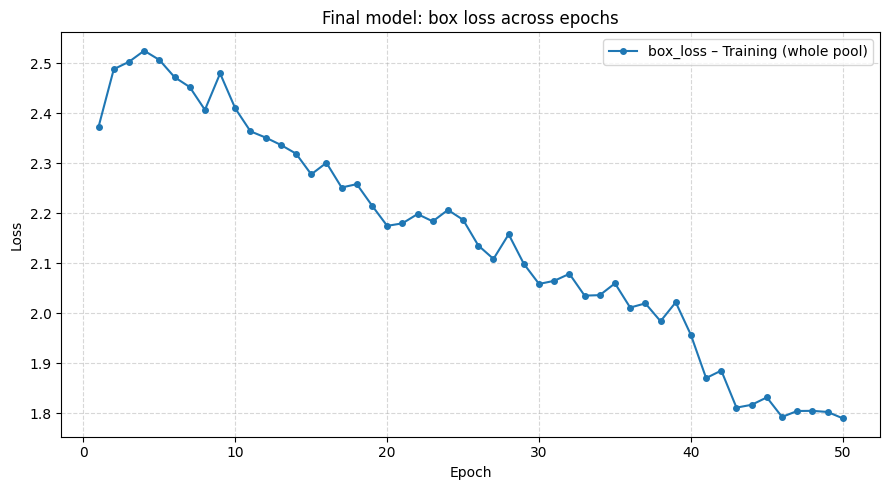

✅ Final model saved: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/modelo_final/weights/modelo_final.pt


In [ ]:
# ======================================================
# 10. Final single model: RETRAIN on the WHOLE pool (train + val of IL and ML, no hold-out fold)
#     - Same hyperparameters, seed and number of epochs as the fold models.
#     - There is no validation set left, so validation during training is disabled (val=False)
#       and the weights of the LAST epoch are used (no best-epoch selection).
#     - Expected generalisation = cross-validation results of cell 9 + independent test sets (cell 11).
# ======================================================
FINAL_PROJ = os.path.join(RESULTS_DIR, 'modelo_final')
FINAL_RUN = 'treino_pool_completo'
MODELO_FINAL_DIR = os.path.join(FINAL_PROJ, 'weights')
os.makedirs(MODELO_FINAL_DIR, exist_ok=True)
MODELO_FINAL = os.path.join(MODELO_FINAL_DIR, 'modelo_final.pt')

# YAML: every pool image for training. 'val' points to the same list only because Ultralytics requires the key
# (in-sample, ignore any metric it prints; validation during training is turned off).
f_all = os.path.join(FOLDS_DIR, 'pool_completo_train.txt')
with open(f_all, 'w') as f:
    f.write('\n'.join(caminho_pool(n) for n in pool_df['new_name']) + '\n')
YAML_POOL = escrever_yaml(os.path.join(UNI_BASE, 'pool_completo.yaml'), f_all, f_all)

run_final = os.path.join(FINAL_PROJ, FINAL_RUN)
last_pt = os.path.join(run_final, 'weights', 'last.pt')
res_csv = os.path.join(run_final, 'results.csv')

concluido = bool(RETOMAR and os.path.exists(last_pt) and os.path.exists(res_csv)
                 and len(pd.read_csv(res_csv)) >= EPOCHS)

if concluido:
    print(f"⏭️  Final model: training already completed, skipping -> {run_final}")
else:
    print(f"\n🚀 Final model: training on {len(pool_df)} images (Ultralytics {ultralytics.__version__})...")
    model = YOLO('yolo26m.pt')
    model.train(
        data=YAML_POOL,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        seed=SEED,
        deterministic=True,
        val=False,                 # no validation set; final-epoch weights are used
        project=FINAL_PROJ,
        name=FINAL_RUN,
        exist_ok=True,
        save_period=-1,
        plots=True
    )
    run_final = str(model.trainer.save_dir)
    last_pt = os.path.join(run_final, 'weights', 'last.pt')
    res_csv = os.path.join(run_final, 'results.csv')
    del model
    torch.cuda.empty_cache()

shutil.copy(last_pt, MODELO_FINAL)

# Training loss curve of the final model
res_f = pd.read_csv(res_csv)
res_f.columns = res_f.columns.str.strip()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(res_f['epoch'].astype(int), res_f['train/box_loss'], '-o', ms=4, label='box_loss – Training (whole pool)')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.set_title('Final model: box loss across epochs')
ax.grid(linestyle='--', alpha=0.5); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FINAL_PROJ, 'loss_curve_per_epoch.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Final model saved: {MODELO_FINAL}")

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.2 ms, read: 59.8±6.9 MB/s, size: 99.9 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/test_IL/labels.cache... 150 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 25.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 26.1s/it 4:21
                   all        150       2317      0.784      0.657       0.72      0.375
           A_AUSTRALIS         49        832      0.696      0.459      0.535      0.218
          O_FLAVESCENS        128       1485      0.871      0.855      0.904      0.532
Speed: 8.1ms preprocess, 1717.8ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/drive/MyDrive/Colab Notebooks/

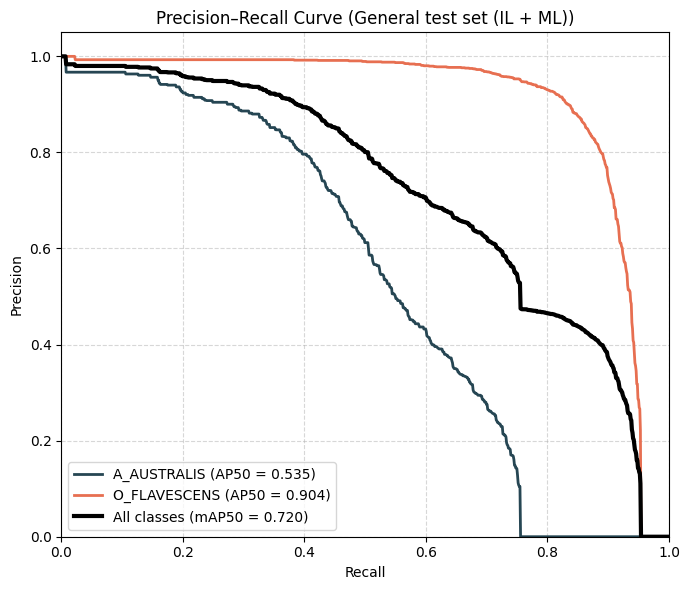

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 77.7±15.3 MB/s, size: 107.6 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/test_IL/labels... 76 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 160.3it/s 0.5s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/test_IL/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 27.4s/it 2:17
                   all         76       2133      0.779      0.653      0.716      0.362
           A_AUSTRALIS         44        801      0.684      0.449      0.525      0.204
          O_FLAVESCENS         61       1332      0.875      0.857      0.908      0.519
Speed: 8.1

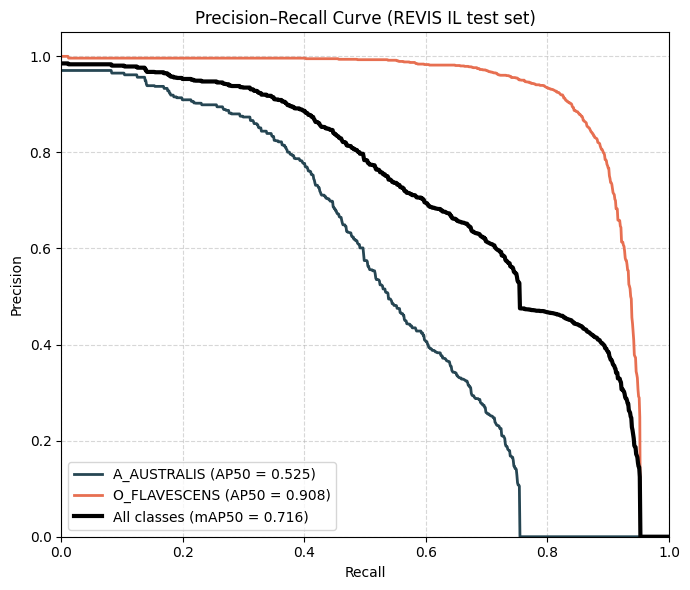

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.9±0.8 ms, read: 55.0±18.5 MB/s, size: 70.0 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/test_ML/labels... 74 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 74/74 168.3it/s 0.4s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/test_ML/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 26.1s/it 2:11
                   all         74        184      0.923      0.757      0.811      0.552
           A_AUSTRALIS          5         31       0.93       0.71      0.734      0.477
          O_FLAVESCENS         67        153      0.916      0.804      0.888      0.626
Speed: 9.4m

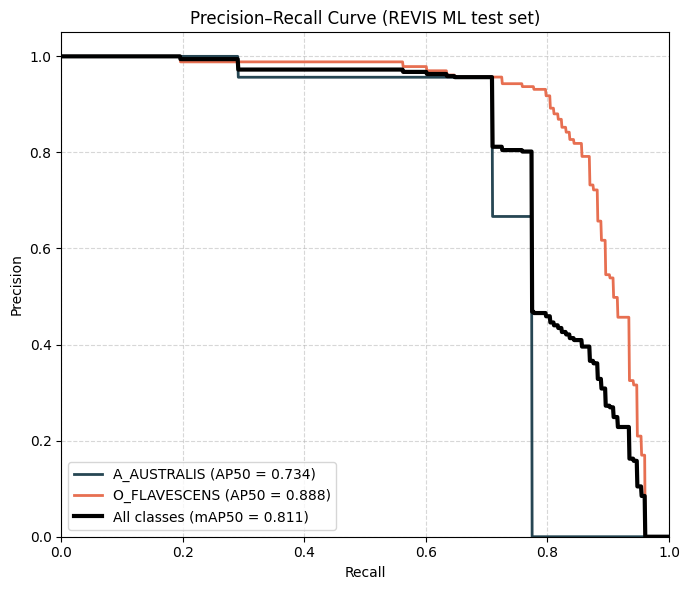


✅ Test results saved under: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML


In [6]:
# ======================================================
# 11. Test-set evaluation of the single model (3 ways)
#     1) General test set (IL + ML test images that were held out)
#     2) Test set of REVIS IL only
#     3) Test set of REVIS ML only
#     The confidence threshold (cell 9) is applied as is; nothing is tuned on test data.
#     - mAP and PR curves: computed with the default low confidence (correct for AP).
#     - Confusion matrix: ALSO produced at the operating threshold (best_conf),
#       which is the one that should be reported (far fewer background false positives).
# ======================================================
import os
import json
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---- Fallbacks if this cell is run in a fresh session (after the training cells) ----
ROOT = globals().get('ROOT', '/content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo')
RESULTS_DIR = globals().get('RESULTS_DIR', os.path.join(ROOT, 'Resultados_Modelo_Unico_IL_ML'))
UNI_BASE = globals().get('UNI_BASE', os.path.join(ROOT, 'Modelo_Unico_IL_ML'))
IMGSZ = globals().get('IMGSZ', 640)
CLASS_NAMES = globals().get('CLASS_NAMES', ['A_AUSTRALIS', 'O_FLAVESCENS'])

MODELO_FINAL = globals().get('MODELO_FINAL', os.path.join(RESULTS_DIR, 'modelo_final', 'weights', 'modelo_final.pt'))
best_conf = globals().get('best_conf', 0.304)
confs_fold = globals().get('confs_fold', {1: 0.293, 2: 0.310, 3: 0.308})

YAML_TESTE = globals().get('YAML_TESTE', {
    'teste_geral': os.path.join(UNI_BASE, 'test_geral.yaml'),
    'teste_IL':    os.path.join(UNI_BASE, 'test_IL.yaml'),
    'teste_ML':    os.path.join(UNI_BASE, 'test_ML.yaml'),
})

# Ensure test dataframe is available for image counting
if 'test_df' not in globals():
    # Attempt to reload pool_folds.csv or dataset_summary.csv if available
    test_df_path = os.path.join(RESULTS_DIR, 'pool_folds.csv')
    if os.path.exists(test_df_path):
        # fallback using original test count distributions
        test_df = pd.DataFrame([{'area': 'IL'}] * 76 + [{'area': 'ML'}] * 74)
    else:
        test_df = pd.DataFrame([{'area': 'IL'}] * 76 + [{'area': 'ML'}] * 74)
else:
    test_df = globals()['test_df']

# Fallback helper function if run in a fresh session
if 'tabela_metricas' not in globals():
    def tabela_metricas(b, conf):
        """Per-class and macro-average metrics at a given confidence threshold."""
        idx = int(np.abs(b.px - conf).argmin())
        rows = []
        for k, c in enumerate(b.ap_class_index):
            rows.append({
                'Class': CLASS_NAMES[c],
                'mAP50': b.ap50[k],
                'mAP50-95': b.ap[k],
                'Precision': b.p_curve[k, idx],
                'Recall': b.r_curve[k, idx],
                'F1-Score': b.f1_curve[k, idx],
            })
        rows.insert(0, {
            'Class': 'all',
            'mAP50': b.map50,
            'mAP50-95': b.map,
            'Precision': np.mean([r['Precision'] for r in rows]),
            'Recall': np.mean([r['Recall'] for r in rows]),
            'F1-Score': np.mean([r['F1-Score'] for r in rows]),
        })
        return pd.DataFrame(rows)
else:
    tabela_metricas = globals()['tabela_metricas']

def avaliar_teste(model_path, yaml_path, nome, conf, plots=True):
    out_dir = os.path.join(RESULTS_DIR, nome)
    os.makedirs(out_dir, exist_ok=True)

    # (1) Main evaluation: low default confidence -> correct mAP and PR curves
    mt = YOLO(model_path).val(
        data=yaml_path,
        split='test',
        imgsz=IMGSZ,
        plots=plots,
        project=RESULTS_DIR,
        name=nome,
        exist_ok=True
    )
    b = mt.box
    df_t = tabela_metricas(b, conf)

    # (2) Confusion matrix at the operating threshold (best_conf): only the matrices are kept
    mc = YOLO(model_path).val(
        data=yaml_path,
        split='test',
        imgsz=IMGSZ,
        conf=conf,
        plots=True,
        project=RESULTS_DIR,
        name=f'{nome}_tmp_matriz',
        exist_ok=True
    )
    tmp_dir = str(mc.save_dir)
    for src, dst in [('confusion_matrix.png', f'confusion_matrix_conf{conf:.3f}.png'),
                     ('confusion_matrix_normalized.png', f'confusion_matrix_normalized_conf{conf:.3f}.png')]:
        if os.path.exists(os.path.join(tmp_dir, src)):
            shutil.copy(os.path.join(tmp_dir, src), os.path.join(out_dir, dst))
    shutil.rmtree(tmp_dir, ignore_errors=True)

    return b, df_t, out_dir

AVALIACOES = {
    'teste_geral': 'General test set (IL + ML)',
    'teste_IL':    'REVIS IL test set',
    'teste_ML':    'REVIS ML test set',
}
CORES = ['#264653', '#e76f51']

def n_imagens_teste(nome):
    if nome == 'teste_geral':
        return int(len(test_df))
    return int((test_df['area'] == nome.split('_')[1]).sum())

for nome, titulo in AVALIACOES.items():
    b, df_t, out_dir = avaliar_teste(MODELO_FINAL, YAML_TESTE[nome], nome, best_conf)

    df_t.to_csv(os.path.join(out_dir, 'metricas_teste.csv'), index=False, encoding='utf-8-sig')
    with open(os.path.join(out_dir, 'metricas_teste_info.json'), 'w') as f:
        json.dump({
            'avaliacao': titulo,
            'confidence_threshold': best_conf,
            'confidence_threshold_por_fold': confs_fold,
            'num_test_images': n_imagens_teste(nome),
            'modelo': MODELO_FINAL,
        }, f, indent=2, ensure_ascii=False)

    print("\n" + "=" * 70)
    print(f"╴ {titulo.upper()}  (n = {n_imagens_teste(nome)} images)")
    print("=" * 70)
    print(df_t.round(4).to_string(index=False))

    # Precision–Recall curve
    fig, ax = plt.subplots(figsize=(7, 6))
    for k, c in enumerate(b.ap_class_index):
        ax.plot(b.px, b.prec_values[k], color=CORES[c], lw=2,
                label=f'{CLASS_NAMES[c]} (AP50 = {b.ap50[k]:.3f})')
    ax.plot(b.px, b.prec_values.mean(0), color='black', lw=3, label=f'All classes (mAP50 = {b.map50:.3f})')
    ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
    ax.set_title(f'Precision–Recall Curve ({titulo})')
    ax.grid(linestyle='--', alpha=0.5); ax.legend(loc='lower left')
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, 'curva_precision_recall_teste.png'), dpi=300, bbox_inches='tight')
    plt.show()

print(f"\n✅ Test results saved under: {RESULTS_DIR}")

In [ ]:
# ======================================================
# 12. Visual inference on the independent test sets
# ======================================================
model_final = YOLO(MODELO_FINAL)
dfs_pred = {}

for area in ['IL', 'ML']:
    pred_dir = os.path.join(RESULTS_DIR, f'teste_{area}', 'predicoes_teste')
    os.makedirs(pred_dir, exist_ok=True)
    print(f"\n🎯 Exporting REVIS {area} test predictions to: {pred_dir}")

    rows = []
    stream = model_final.predict(
        source=TEST_IMG_DIRS[area],          # includes negative control samples
        conf=best_conf,
        iou=IOU_PRED,
        imgsz=IMGSZ,
        save=True,
        project=os.path.join(RESULTS_DIR, f'teste_{area}'),
        name='predicoes_teste',
        exist_ok=True,
        stream=True,
        verbose=False
    )
    for r in stream:
        cls = r.boxes.cls.cpu().numpy().astype(int)
        rows.append({
            'image': os.path.basename(r.path),
            'area': area,
            'A_AUSTRALIS': int((cls == 0).sum()),
            'O_FLAVESCENS': int((cls == 1).sum())
        })
    dfs_pred[area] = pd.DataFrame(rows)
    dfs_pred[area].drop(columns='area').to_csv(os.path.join(pred_dir, 'deteccoes_por_imagem_teste.csv'), index=False)
    print(f"✅ {len(rows)} images processed")

# General test set: concatenation of both areas
geral_dir = os.path.join(RESULTS_DIR, 'teste_geral', 'predicoes_teste')
os.makedirs(geral_dir, exist_ok=True)
pd.concat(dfs_pred.values(), ignore_index=True).to_csv(
    os.path.join(geral_dir, 'deteccoes_por_imagem_teste.csv'), index=False)
print(f"📸 Annotated images are stored in teste_IL/predicoes_teste and teste_ML/predicoes_teste")


🎯 Exporting REVIS IL test predictions to: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/teste_IL/predicoes_teste
Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/teste_IL/predicoes_teste
✅ 76 images processed

🎯 Exporting REVIS ML test predictions to: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/teste_ML/predicoes_teste
Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/teste_ML/predicoes_teste
✅ 74 images processed
📸 Annotated images are stored in teste_IL/predicoes_teste and teste_ML/predicoes_teste


In [ ]:
# ======================================================
# 13. Sanity check: final (full-pool) model vs the K fold models on the test sets
#     (the final model should be at least as good as the fold models, which saw less data)
# ======================================================
comp = []
modelos_comp = {f'Fold {k} model': best_pts[k] for k in range(1, K_FOLDS + 1)}
modelos_comp['Final model (whole pool)'] = MODELO_FINAL

for nome_modelo, caminho in modelos_comp.items():
    for nome, titulo in AVALIACOES.items():
        m = YOLO(caminho).val(data=YAML_TESTE[nome], split='test', imgsz=IMGSZ, plots=False, verbose=False,
                              project=RESULTS_DIR, name='tmp_cmp', exist_ok=True)
        t = tabela_metricas(m.box, best_conf).iloc[0]
        comp.append({'Model': nome_modelo, 'Test set': titulo,
                     'mAP50': t['mAP50'], 'mAP50-95': t['mAP50-95'],
                     'Precision': t['Precision'], 'Recall': t['Recall'], 'F1-Score': t['F1-Score']})
shutil.rmtree(os.path.join(RESULTS_DIR, 'tmp_cmp'), ignore_errors=True)

df_comp = pd.DataFrame(comp)
df_comp.to_csv(os.path.join(RESULTS_DIR, 'comparacao_modelos_teste.csv'), index=False, encoding='utf-8-sig')
print(df_comp.round(4).to_string(index=False))

# ======================================================
# Checkpoint verification
# ======================================================
assert os.path.exists(MODELO_FINAL), f"❌ Checkpoint not found: {MODELO_FINAL}"
print(f"\n✅ Final (whole-pool) checkpoint verified: {MODELO_FINAL}")
print(f"✅ All outputs saved in: {RESULTS_DIR}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 77.7±18.4 MB/s, size: 84.4 KB)
val: Scanning /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/test_IL/labels... 150 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 214.9it/s 0.7s
val: New cache created: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Modelo_Unico_IL_ML/test_IL/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.7it/s 5.9s
                   all        150       2317      0.772       0.65       0.71      0.357
Speed: 1.3ms preprocess, 32.0ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (f

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 231ms
Prepared 1 package in 51ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/video_botsort_IL

🎬 [IL] Survey video: DJI 0551_Teste contagem.mp4
🐾 Quantified individuals (validated trajectories):
A. australis : 28
O. flavescens: 18
Total trajectories: 48 | Filtered out by criteria: 2

🔎 [IL] Filter sensitivity evaluation (compare against human counts):
 min_len  min_conf  A_AUSTRALIS  O_FLAVESCENS  total
       1       0.1           29            19     48
       1       0.3           28            18     46
       1       0.5           10            12     22
       3       0.1   

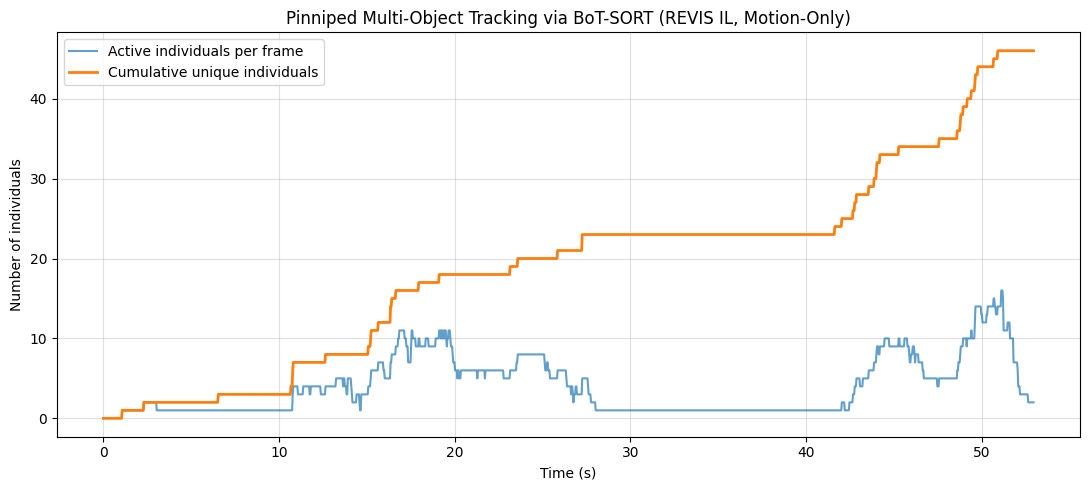

Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/video_botsort_ML

🎬 [ML] Survey video: Molhe Leste_Teste_1.mp4
🐾 Quantified individuals (validated trajectories):
A. australis : 0
O. flavescens: 20
Total trajectories: 20 | Filtered out by criteria: 0

🔎 [ML] Filter sensitivity evaluation (compare against human counts):
 min_len  min_conf  A_AUSTRALIS  O_FLAVESCENS  total
       1       0.1            0            20     20
       1       0.3            0            20     20
       1       0.5            0            16     16
       3       0.1            0            20     20
       3       0.3            0            20     20
       3       0.5            0            16     16
       5       0.1            0            20     20
       5       0.3            0            20     20
       5       0.5            0            16     16
      10       0.1            0            20     20
      10    

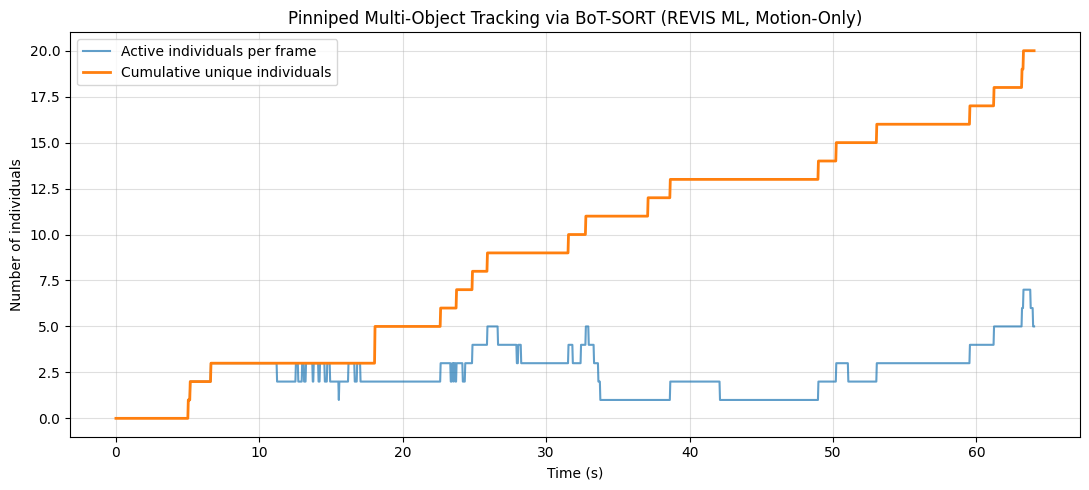

In [ ]:
# ======================================================
# 14. BoT-SORT: Multi-Object Tracking & Individual Counting (single model, both areas)
# ======================================================
import collections
import glob
import json
import math
import os
import shutil
import subprocess

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from ultralytics import YOLO

# ---- Fallbacks if this cell is run in a fresh session (after the training cells) ----
ROOT = globals().get('ROOT', '/content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo')
RESULTS_DIR = globals().get('RESULTS_DIR', os.path.join(ROOT, 'Resultados_Modelo_Unico_IL_ML'))
IMGSZ = globals().get('IMGSZ', 640)
MODELO_FINAL = globals().get('MODELO_FINAL', os.path.join(RESULTS_DIR, 'modelo_final', 'weights', 'modelo_final.pt'))
assert os.path.exists(MODELO_FINAL), f"❌ Final model not found: {MODELO_FINAL}"

BOTSORT_DIR = os.path.join(RESULTS_DIR, 'BoT-SORT')
os.makedirs(BOTSORT_DIR, exist_ok=True)

# ---- Videos and clips of each area (clips do not depend on the model: existing ones are re-used) ----
VIDEOS_TESTE = {
    'IL': '/content/drive/MyDrive/Colab Notebooks/YOLO/DJI 0551_Teste contagem.mp4',
    'ML': os.path.join(ROOT, 'REVIS_ML_Negativo', 'Molhe Leste_Teste_1.mp4'),
}
AREAS = {
    'IL': dict(
        video_in=os.path.join(ROOT, 'Resultados_REVIS_IL', 'BoT-SORT', 'REVIS_IL', 'DJI_20261113085548_0001_V.MP4'),
        dir_clips=os.path.join(ROOT, 'Resultados_REVIS_IL', 'BoT-SORT', 'REVIS_IL_dividido'),
    ),
    'ML': dict(
        video_in=os.path.join(ROOT, 'Resultados_REVIS_ML', 'BoT-SORT', 'Videos_divididos',
                              'Lateral_interna_dividido', 'DJI_20261113090657_0001_V_clipe01.MP4'),
        dir_clips=os.path.join(ROOT, 'Resultados_REVIS_ML', 'BoT-SORT', 'Videos_divididos', 'Lateral_interna_dividido'),
    ),
}

CONF_DET = 0.1             # Low confidence threshold: enables BoT-SORT secondary association
MIN_LEN, MIN_CONF = 5, 0.3 # Valid track criterion: >= MIN_LEN frames and mean confidence >= MIN_CONF

BOTSORT_BASE = dict(
    tracker_type='botsort',
    track_high_thresh=0.5,       # Primary high-confidence association threshold
    track_low_thresh=0.1,        # Secondary low-confidence association threshold
    new_track_thresh=0.6,        # Confidence threshold required to initialise a new track
    track_buffer=60,             # Number of frames an unmatched track is retained in memory
    match_thresh=0.8,            # Spatial matching threshold (IoU)
    fuse_score=True,
    gmc_method='sparseOptFlow',  # Camera motion compensation via sparse optical flow
    proximity_thresh=0.5,
    appearance_thresh=0.25,
    with_reid=False,             # Operates in motion-only mode (no visual ReID features)
    model='auto'
)


def save_yaml(cfg, path):
    """Serialises tracker configuration to a local YAML file."""
    with open(path, 'w') as f:
        yaml.safe_dump(cfg, f)
    return path


def count_tracks(df_tr, min_len=5, min_conf=0.3):
    """
    Quantifies unique individuals: tracks with >= min_len frames and mean confidence >= min_conf.
    The species class assigned to each trajectory is determined by majority vote.
    """
    zeros = pd.Series([0, 0], index=[0, 1])
    if df_tr.empty:
        return zeros, pd.DataFrame()

    tracks = df_tr.groupby('id').agg(
        n_frames=('frame', 'count'),
        mean_conf=('conf', 'mean'),
        species_class=('cls', lambda s: s.mode().iloc[0]),
        start_frame=('frame', 'min'),
        end_frame=('frame', 'max')
    ).reset_index()

    valid = tracks[(tracks['n_frames'] >= min_len) & (tracks['mean_conf'] >= min_conf)]
    counts = valid['species_class'].value_counts().reindex([0, 1], fill_value=0)
    return counts, tracks


def run_botsort(video, yml, run_name, project, conf_det=CONF_DET, save_video=True):
    """
    Tracks a video with the single YOLO26m model + BoT-SORT.
    A fresh model is instantiated on every call to reset the internal tracker state.
    Returns (detections with track ID, number of frames processed).
    """
    m = YOLO(MODELO_FINAL)
    stream = m.track(
        source=video,
        tracker=yml,
        conf=conf_det,
        iou=0.6,
        imgsz=IMGSZ,
        save=save_video,
        project=project,
        name=run_name,
        exist_ok=True,
        stream=True,
        verbose=False
    )
    rows, n_read = [], 0
    for i, r in enumerate(stream):
        n_read = i + 1
        if r.boxes.id is None:
            continue
        ids = r.boxes.id.cpu().numpy().astype(int)
        cls = r.boxes.cls.cpu().numpy().astype(int)
        cf = r.boxes.conf.cpu().numpy()
        xy = r.boxes.xyxy.cpu().numpy()
        for t, c, s, b in zip(ids, cls, cf, xy):
            rows.append((i, int(t), float(s), int(c), *map(float, b)))
    return pd.DataFrame(rows, columns=['frame', 'id', 'conf', 'cls', 'x1', 'y1', 'x2', 'y2']), n_read


yml_botsort = save_yaml(BOTSORT_BASE, os.path.join(BOTSORT_DIR, 'botsort_config.yaml'))

# ------------------------------------------------------
# Run the tracker on the survey test video of each area
# ------------------------------------------------------
for area, video_input_path in VIDEOS_TESTE.items():
    if not os.path.exists(video_input_path):
        print(f"⚠️ [{area}] Survey video not found, skipped: {video_input_path}")
        continue

    run_name = f'video_botsort_{area}'
    out = os.path.join(BOTSORT_DIR, run_name)
    os.makedirs(out, exist_ok=True)

    df_tr, _ = run_botsort(video_input_path, yml_botsort, run_name, BOTSORT_DIR)
    if df_tr.empty:
        print(f"⚠️ [{area}] No detections tracked. Check the video path, the weights, or lower CONF_DET.")
        continue

    counts, tracks = count_tracks(df_tr, MIN_LEN, MIN_CONF)
    df_tr.to_csv(os.path.join(out, 'detections_with_id.csv'), index=False)
    tracks.to_csv(os.path.join(out, 'trajectories.csv'), index=False)

    print(f"\n🎬 [{area}] Survey video: {os.path.basename(video_input_path)}")
    print("🐾 Quantified individuals (validated trajectories):")
    print(f"A. australis : {counts[0]}")
    print(f"O. flavescens: {counts[1]}")
    print(f"Total trajectories: {len(tracks)} | Filtered out by criteria: {len(tracks) - counts.sum()}")

    # Export parameter metadata (for Methodology documentation)
    with open(os.path.join(out, 'botsort_parameters.json'), 'w') as f:
        json.dump({
            'area': area,
            'survey_video': os.path.basename(video_input_path),
            'model': MODELO_FINAL,
            'tracker_config': BOTSORT_BASE,
            'detection_conf_threshold': CONF_DET,
            'min_track_length_frames': MIN_LEN,
            'min_mean_confidence': MIN_CONF,
            'final_counts': {'A_AUSTRALIS': int(counts[0]), 'O_FLAVESCENS': int(counts[1])}
        }, f, indent=2)

    # Filter sensitivity analysis (computed without reprocessing the video)
    sens = []
    for ml in (1, 3, 5, 10, 15, 30):
        for mc in (0.1, 0.3, 0.5):
            c, _ = count_tracks(df_tr, ml, mc)
            sens.append({'min_len': ml, 'min_conf': mc, 'A_AUSTRALIS': int(c[0]),
                         'O_FLAVESCENS': int(c[1]), 'total': int(c.sum())})
    df_sens = pd.DataFrame(sens)
    df_sens.to_csv(os.path.join(out, 'filter_sensitivity_analysis.csv'), index=False)
    print(f"\n🔎 [{area}] Filter sensitivity evaluation (compare against human counts):")
    print(df_sens.to_string(index=False))

    # Time-series: per-frame count vs cumulative unique tracks
    cap = cv2.VideoCapture(video_input_path)
    fps_v = cap.get(cv2.CAP_PROP_FPS)
    cap.release()

    valid_ids = tracks[(tracks['n_frames'] >= MIN_LEN) & (tracks['mean_conf'] >= MIN_CONF)]['id']
    dfv = df_tr[df_tr['id'].isin(valid_ids)]
    if dfv.empty:
        print(f"⚠️ [{area}] No valid tracks available for time-series plotting under current filters.")
        continue

    per_frame = dfv.groupby('frame')['id'].nunique()
    first_occurrence = dfv.groupby('id')['frame'].min().value_counts().sort_index().cumsum()
    first_occurrence = first_occurrence.reindex(range(int(df_tr['frame'].max()) + 1)).ffill().fillna(0)

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(per_frame.index / fps_v, per_frame.values, label='Active individuals per frame', alpha=0.7)
    ax.plot(first_occurrence.index / fps_v, first_occurrence.values, label='Cumulative unique individuals', lw=2)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Number of individuals')
    ax.set_title(f'Pinniped Multi-Object Tracking via BoT-SORT (REVIS {area}, Motion-Only)')
    ax.grid(alpha=0.4)
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(out, 'botsort_trajectory_counts.png'), dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
# ======================================================
# 15. Split a video into fixed-duration clips (per area)
#     Clips do not depend on the model: if the clip folder of an area already contains clips,
#     they are re-used and nothing is split (set FORCAR_DIVISAO = True to split again).
# ======================================================
CLIP_DUR_S = 60          # Duration of each clip (s)
FORCAR_DIVISAO = False

for area, cfg in AREAS.items():
    video_in, dir_clips = cfg['video_in'], cfg['dir_clips']
    os.makedirs(dir_clips, exist_ok=True)

    existentes = glob.glob(os.path.join(dir_clips, '*.mp4')) + glob.glob(os.path.join(dir_clips, '*.MP4'))
    if existentes and not FORCAR_DIVISAO:
        print(f"⏭️  [{area}] {len(existentes)} clips already in {dir_clips} - re-using them")
        continue

    cap = cv2.VideoCapture(video_in)
    if not cap.isOpened():
        print(f"⚠️ [{area}] Could not open the video (check the path or that Google Drive is mounted): {video_in}")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps == 0:
        cap.release()
        print(f"⚠️ [{area}] FPS returned by the video is zero (corrupted file?): {video_in}")
        continue

    total_dur = cap.get(cv2.CAP_PROP_FRAME_COUNT) / fps
    cap.release()

    n = math.ceil(total_dur / CLIP_DUR_S)  # Retains the final remainder shorter than a full clip
    stem = os.path.splitext(os.path.basename(video_in))[0]

    for k in range(n):
        output_path = os.path.join(dir_clips, f'{stem}_clip{k+1:02d}.mp4')
        subprocess.run([
            'ffmpeg', '-y', '-loglevel', 'error',
            '-ss', str(k * CLIP_DUR_S),
            '-i', video_in,
            '-t', str(CLIP_DUR_S),
            '-an', '-c:v', 'libx264', '-preset', 'veryfast', '-crf', '18',
            output_path
        ], check=True)
        print(f'[{area}] Saved: {os.path.basename(output_path)}')

    print(f'\n✂️ [{area}] {n} clips of {CLIP_DUR_S} s saved to: {dir_clips}')

⏭️  [IL] 6 clips already in /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_REVIS_IL/BoT-SORT/REVIS_IL_dividido - re-using them
⏭️  [ML] 6 clips already in /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_REVIS_ML/BoT-SORT/Videos_divididos/Lateral_interna_dividido - re-using them


In [ ]:
# ======================================================
# 16. Batch BoT-SORT: Tracking + Individual Counting per Clip (single model, both areas)
# ======================================================
MIN_DUR_S = 0                    # Clips shorter than this threshold (e.g. final video remainder) are skipped
SAVE_VIDEO = True                # False = faster execution; skips saving annotated videos to Google Drive

OUT_ROOTS = {a: os.path.join(BOTSORT_DIR, f'Results_{a}') for a in AREAS}
CLIPS_DIRS = {a: cfg['dir_clips'] for a, cfg in AREAS.items()}


def listar_clips(d):
    return sorted(glob.glob(os.path.join(d, '*.mp4')) + glob.glob(os.path.join(d, '*.MP4')))


for area in AREAS:
    OUT_ROOT, CLIPS_DIR = OUT_ROOTS[area], CLIPS_DIRS[area]
    clips = listar_clips(CLIPS_DIR)
    if not clips:
        print(f"⚠️ [{area}] No .mp4 clips found in: {CLIPS_DIR} (skipped)")
        continue
    os.makedirs(OUT_ROOT, exist_ok=True)

    summary_rows = []
    for k, clip in enumerate(clips, 1):
        name = os.path.basename(clip)
        stem = os.path.splitext(name)[0].replace(' ', '_')
        cap = cv2.VideoCapture(clip)
        fps_v = cap.get(cv2.CAP_PROP_FPS)
        n_fr = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()
        dur = n_fr / fps_v if fps_v else 0
        if dur < MIN_DUR_S:
            print(f"⏭️ [{area} {k}/{len(clips)}] {name}: {dur:.1f} s (< {MIN_DUR_S} s), skipped")
            continue

        df_tr, n_read = run_botsort(clip, yml_botsort, stem, OUT_ROOT, save_video=SAVE_VIDEO)
        counts, tracks = count_tracks(df_tr, MIN_LEN, MIN_CONF)
        out = os.path.join(OUT_ROOT, stem)
        os.makedirs(out, exist_ok=True)
        df_tr.to_csv(os.path.join(out, 'detections_with_id.csv'), index=False)
        tracks.to_csv(os.path.join(out, 'trajectories.csv'), index=False)

        summary_rows.append({
            'area': area,
            'clip': name,
            'A_AUSTRALIS': int(counts[0]),
            'O_FLAVESCENS': int(counts[1]),
            'total': int(counts.sum()),
            'total_tracks': len(tracks),
            'frames': n_read,
            'fps': round(fps_v, 3),
            'duration_s': round(n_read / fps_v, 1) if fps_v else 0.0
        })
        print(
            f"✅ [{area} {k}/{len(clips)}] {name}: A. australis={int(counts[0])} | O. flavescens={int(counts[1])} "
            f"| tracks filtered out={len(tracks) - int(counts.sum())}"
        )

    df_auto = pd.DataFrame(summary_rows)
    df_auto.to_csv(os.path.join(OUT_ROOT, 'automated_counts.csv'), sep=';', index=False, encoding='utf-8-sig')

    with open(os.path.join(OUT_ROOT, 'botsort_parameters.json'), 'w') as f:
        json.dump({
            'area': area,
            'model': MODELO_FINAL,
            'tracker_config': BOTSORT_BASE,
            'detection_conf_threshold': CONF_DET,
            'min_track_length_frames': MIN_LEN,
            'min_mean_confidence': MIN_CONF,
            'min_clip_duration_s': MIN_DUR_S
        }, f, indent=2)

    print(f"\n🐾 [{area}] Automated counts per clip:")
    if not df_auto.empty:
        print(df_auto[['clip', 'A_AUSTRALIS', 'O_FLAVESCENS', 'total', 'duration_s']].to_string(index=False))
    print(f"📁 [{area}] Results saved to: {OUT_ROOT}\n")

Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/DJI_20261113085548_0001_V_clipe01
✅ [IL 1/6] DJI_20261113085548_0001_V_clipe01.mp4: A. australis=0 | O. flavescens=0 | tracks filtered out=0
Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/DJI_20261113085548_0001_V_clipe02
✅ [IL 2/6] DJI_20261113085548_0001_V_clipe02.mp4: A. australis=2 | O. flavescens=11 | tracks filtered out=0
Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/DJI_20261113085548_0001_V_clipe03
✅ [IL 3/6] DJI_20261113085548_0001_V_clipe03.mp4: A. australis=0 | O. flavescens=19 | tracks filtered out=2
Results saved to /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL

In [ ]:
# ======================================================
# 17. Spreadsheet Templates for MANUAL COUNTING (frames and clips), per area
#     Manual counts already entered for the single-area models do NOT depend on the model:
#     if the new spreadsheets do not exist yet, the old ones are copied (REUSAR_CONTAGEM_MANUAL = True)
#     so that nothing has to be counted twice.
# ======================================================
STEP_S = 6.0                      # Extract one frame every STEP_S seconds (use the SAME interval across all clips)
REUSAR_CONTAGEM_MANUAL = True

# Result folders of the previous single-area notebooks (where the manual spreadsheets were filled in)
OUT_ROOTS_ANTIGOS = {
    'IL': os.path.join(ROOT, 'Resultados_REVIS_IL', 'BoT-SORT', 'Results_' + os.path.basename(CLIPS_DIRS['IL'].rstrip('/'))),
    'ML': os.path.join(ROOT, 'Resultados_REVIS_ML', 'BoT-SORT', 'Results_' + os.path.basename(CLIPS_DIRS['ML'].rstrip('/'))),
}


def read_csv_auto(path):
    """Reads a CSV file automatically detecting ';' or ',' delimiter."""
    with open(path, encoding='utf-8-sig') as f:
        sep = ';' if ';' in f.readline() else ','
    return pd.read_csv(path, sep=sep, encoding='utf-8-sig')


for area in AREAS:
    OUT_ROOT, CLIPS_DIR = OUT_ROOTS[area], CLIPS_DIRS[area]
    f_auto = os.path.join(OUT_ROOT, 'automated_counts.csv')
    if not os.path.exists(f_auto):
        print(f"⚠️ [{area}] automated_counts.csv not found (run cell 16 first); skipped")
        continue

    frames_root_dir = os.path.join(OUT_ROOT, 'frames_to_count')
    clips = listar_clips(CLIPS_DIR)
    auto_names = set(read_csv_auto(f_auto)['clip'])

    f_frames = os.path.join(OUT_ROOT, 'manual_count_frames.csv')
    f_clips = os.path.join(OUT_ROOT, 'manual_count_clips.csv')

    # ---- Re-use manual counts filled in with the previous (single-area) pipeline ----
    if REUSAR_CONTAGEM_MANUAL:
        for fname, destino in [('manual_count_frames.csv', f_frames), ('manual_count_clips.csv', f_clips)]:
            antigo = os.path.join(OUT_ROOTS_ANTIGOS[area], fname)
            if not os.path.exists(destino) and os.path.exists(antigo):
                shutil.copy(antigo, destino)
                print(f"♻️ [{area}] Manual counts copied from the previous pipeline: {fname}")

    frame_rows = []
    for clip in clips:
        name = os.path.basename(clip)
        if name not in auto_names:          # Process only clips actually analysed (short clips were skipped)
            continue
        stem = os.path.splitext(name)[0].replace(' ', '_')
        frame_dir = os.path.join(frames_root_dir, stem)
        os.makedirs(frame_dir, exist_ok=True)

        cap = cv2.VideoCapture(clip)
        fps_v = cap.get(cv2.CAP_PROP_FPS)
        step = max(1, int(round(STEP_S * fps_v)))
        i = 0
        while True:                         # Sequential reading: maintains exact 0-based indexing of the tracker
            ok, frame = cap.read()
            if not ok:
                break
            if i % step == 0:
                cv2.imwrite(os.path.join(frame_dir, f'frame_{i:06d}.jpg'), frame)
                frame_rows.append({'clip': name, 'frame': i, 'time_s': round(i / fps_v, 2)})
            i += 1
        cap.release()
        print(f"🎬 [{area}] {name}: {sum(1 for r in frame_rows if r['clip'] == name)} frames saved")

    # ---- Frame-level spreadsheet (preserves previously entered counts) ----
    new_df = pd.DataFrame(frame_rows, columns=['clip', 'frame', 'time_s'])
    new_df['A_AUSTRALIS'] = np.nan
    new_df['O_FLAVESCENS'] = np.nan
    if os.path.exists(f_frames):
        prev_df = read_csv_auto(f_frames)
        existing_keys = set(zip(prev_df['clip'], prev_df['frame']))
        new_df = new_df[[(c, f) not in existing_keys for c, f in zip(new_df['clip'], new_df['frame'])]]
        new_df = pd.concat([prev_df, new_df], ignore_index=True)
    new_df.to_csv(f_frames, sep=';', index=False, encoding='utf-8-sig')

    # ---- Clip-level spreadsheet (one row per clip) ----
    if os.path.exists(f_clips):
        hc = read_csv_auto(f_clips)
    else:
        hc = pd.DataFrame(columns=['clip', 'A_AUSTRALIS', 'O_FLAVESCENS', 'observer', 'notes'])
    missing = [c for c in sorted(auto_names) if c not in set(hc['clip'])]
    if missing:
        hc = pd.concat([hc, pd.DataFrame({'clip': missing})], ignore_index=True)
    hc.to_csv(f_clips, sep=';', index=False, encoding='utf-8-sig')

    print(f"\n📝 [{area}] Populate A_AUSTRALIS and O_FLAVESCENS (enter 0 when no animals are present; do not leave blank):")
    print(f"   {f_frames}\n   {f_clips}")
    print(f"🖼️ [{area}] Extracted frames for manual counting saved in: {frames_root_dir}\n")

♻️ [IL] Manual counts copied from the previous pipeline: manual_count_frames.csv
♻️ [IL] Manual counts copied from the previous pipeline: manual_count_clips.csv
🎬 [IL] DJI_20261113085548_0001_V_clipe01.mp4: 10 frames saved
🎬 [IL] DJI_20261113085548_0001_V_clipe02.mp4: 10 frames saved
🎬 [IL] DJI_20261113085548_0001_V_clipe03.mp4: 10 frames saved
🎬 [IL] DJI_20261113085548_0001_V_clipe04.mp4: 10 frames saved
🎬 [IL] DJI_20261113085548_0001_V_clipe05.mp4: 10 frames saved
🎬 [IL] DJI_20261113085548_0001_V_clipe06.mp4: 8 frames saved

📝 [IL] Populate A_AUSTRALIS and O_FLAVESCENS (enter 0 when no animals are present; do not leave blank):
   /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/manual_count_frames.csv
   /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/manual_count_clips.csv
🖼️ [IL] Extracted frames for manual counting saved in: /

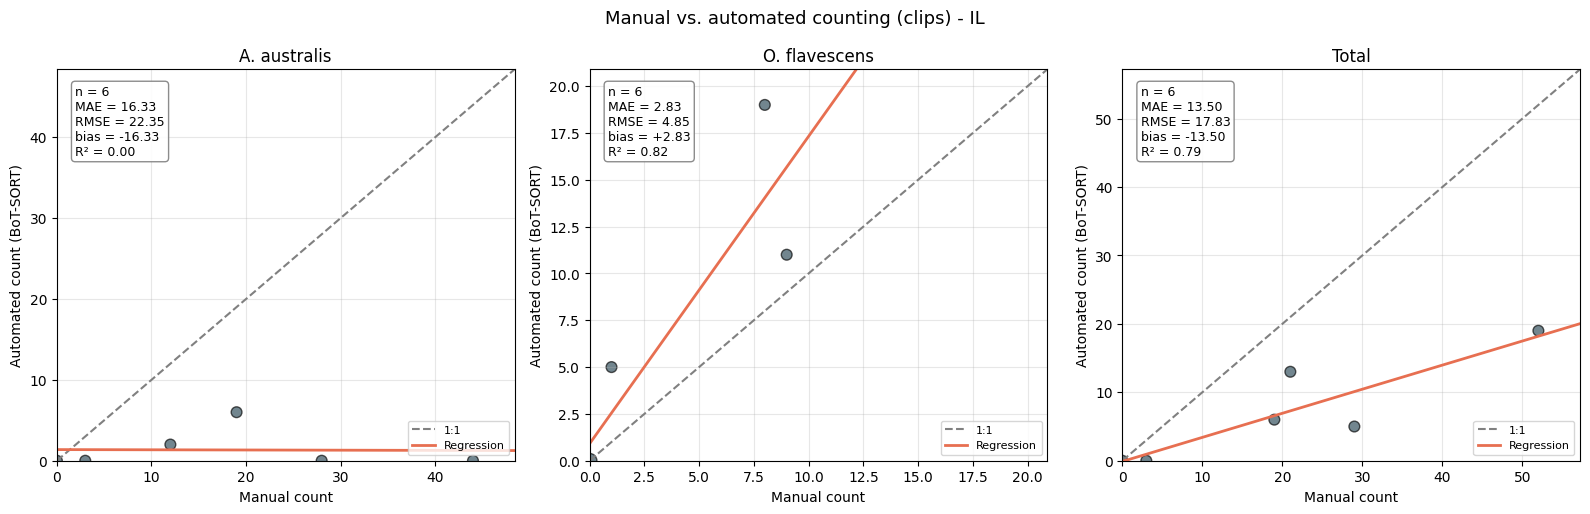

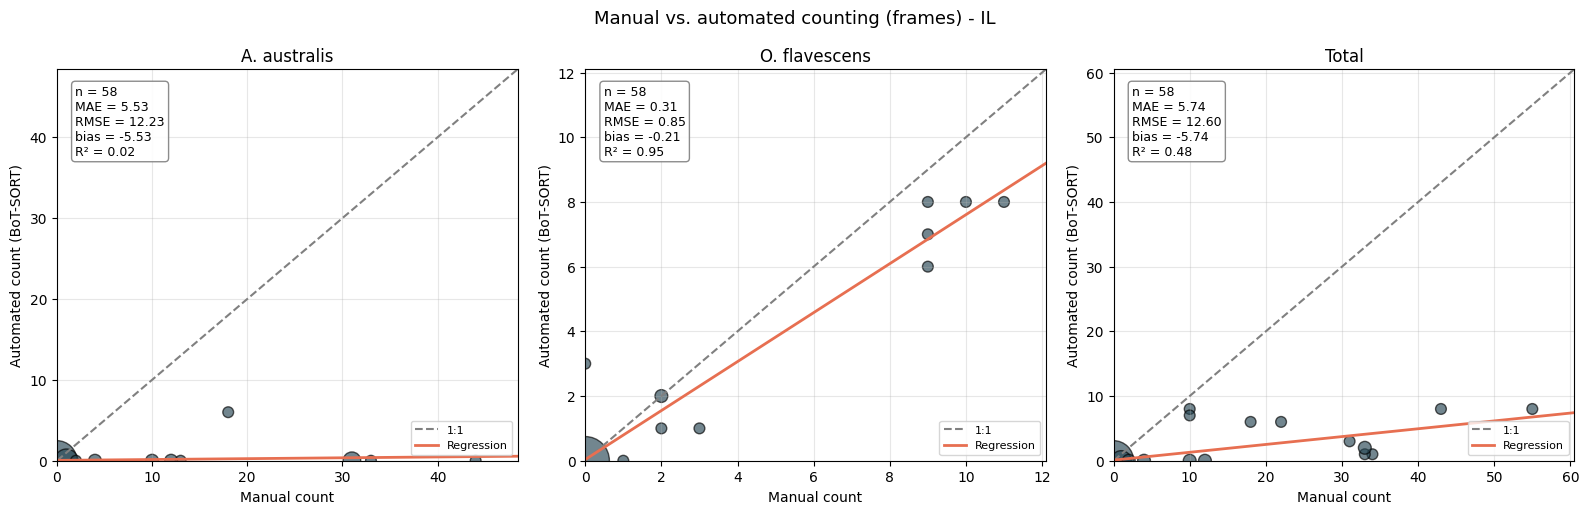


📊 MANUAL vs. AUTOMATED COUNTING - IL (error = automated − manual)
analysis  level         group  n    MAE   RMSE    bias  relative_error_pct  slope  intercept    R2
      IL  clips  A. australis  6 16.333 22.353 -16.333             -92.453 -0.002      1.377 0.000
      IL  clips O. flavescens  6  2.833  4.848   2.833              94.444  1.641      0.909 0.818
      IL  clips         Total  6 13.500 17.828 -13.500             -65.323  0.352     -0.109 0.786
      IL frames  A. australis 58  5.534 12.231  -5.534             -98.165  0.011      0.044 0.022
      IL frames O. flavescens 58  0.310  0.851  -0.207             -20.690  0.757      0.036 0.945
      IL frames         Total 58  5.741 12.595  -5.741             -86.494  0.121      0.092 0.476
📁 Files saved to: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/count_analysis/IL



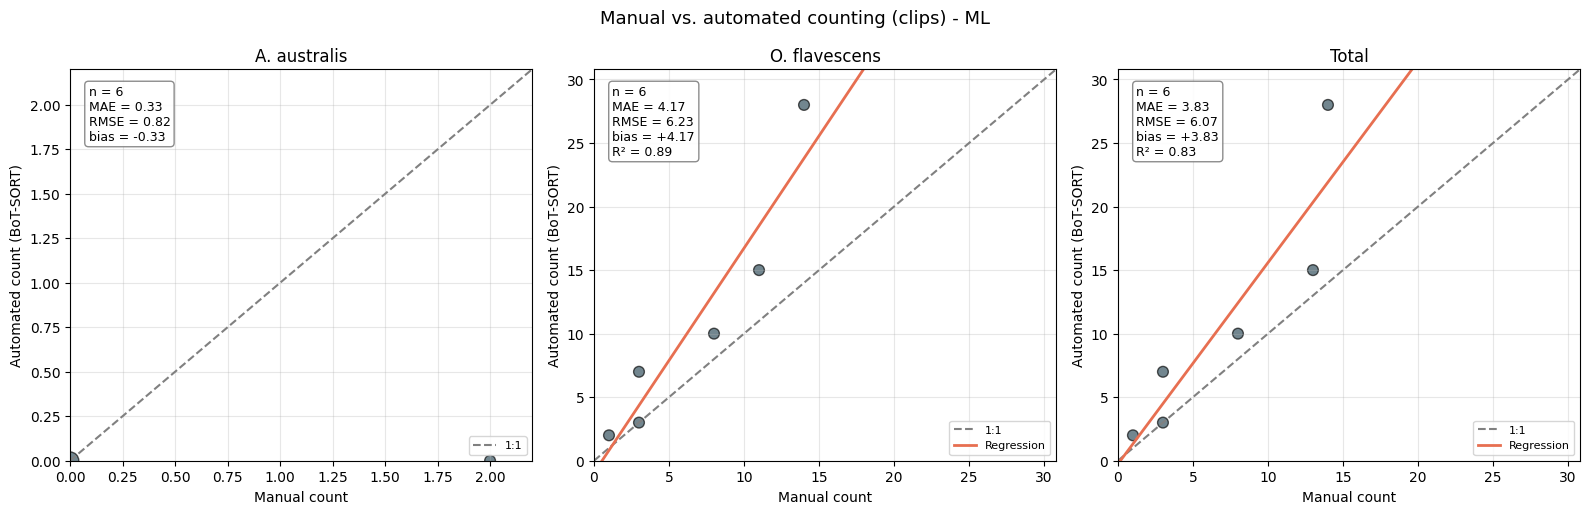

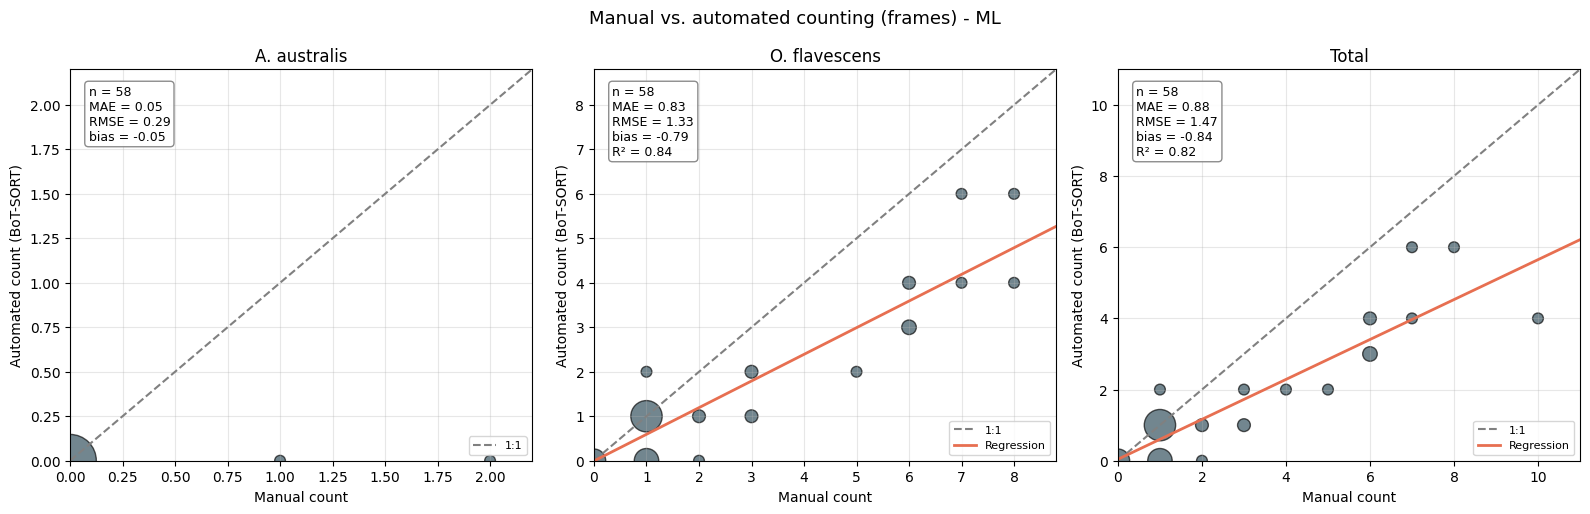


📊 MANUAL vs. AUTOMATED COUNTING - ML (error = automated − manual)
analysis  level         group  n   MAE  RMSE   bias  relative_error_pct  slope  intercept    R2
      ML  clips  A. australis  6 0.333 0.816 -0.333            -100.000  0.000      0.000   NaN
      ML  clips O. flavescens  6 4.167 6.232  4.167              62.500  1.767     -0.950 0.892
      ML  clips         Total  6 3.833 6.069  3.833              54.762  1.584     -0.258 0.828
      ML frames  A. australis 58 0.052 0.294 -0.052            -100.000  0.000      0.000   NaN
      ML frames O. flavescens 58 0.828 1.326 -0.793             -40.351  0.599     -0.005 0.840
      ML frames         Total 58 0.879 1.468 -0.845             -41.880  0.561      0.041 0.816
📁 Files saved to: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/count_analysis/ML



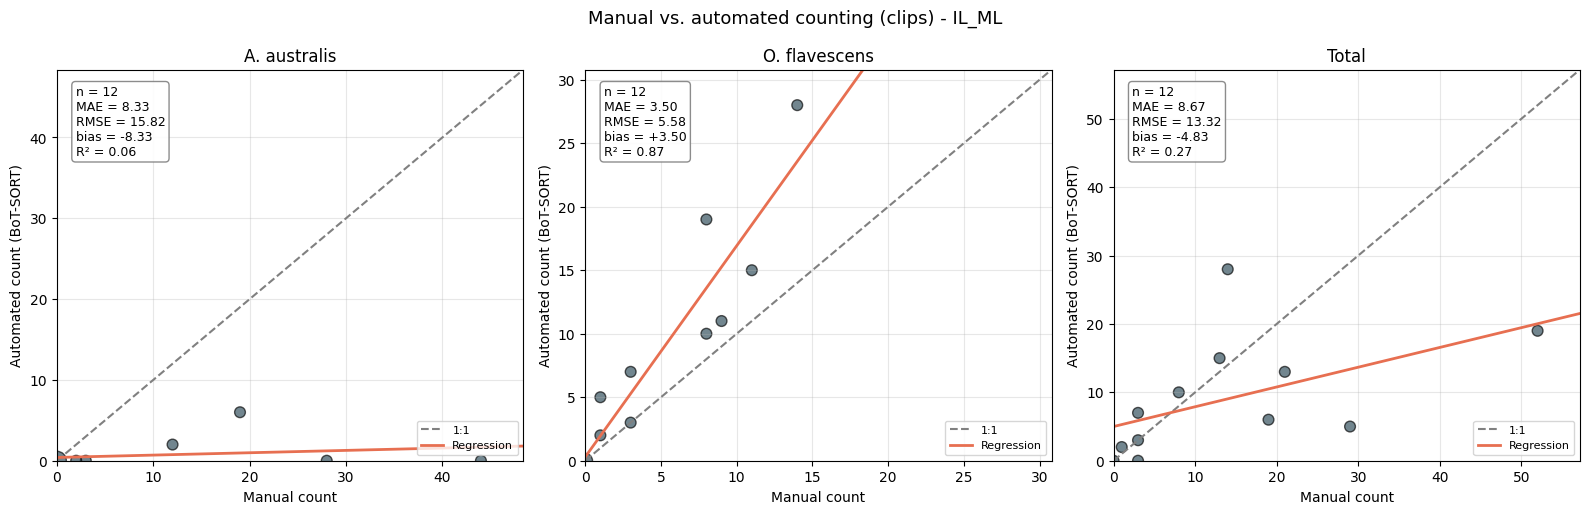

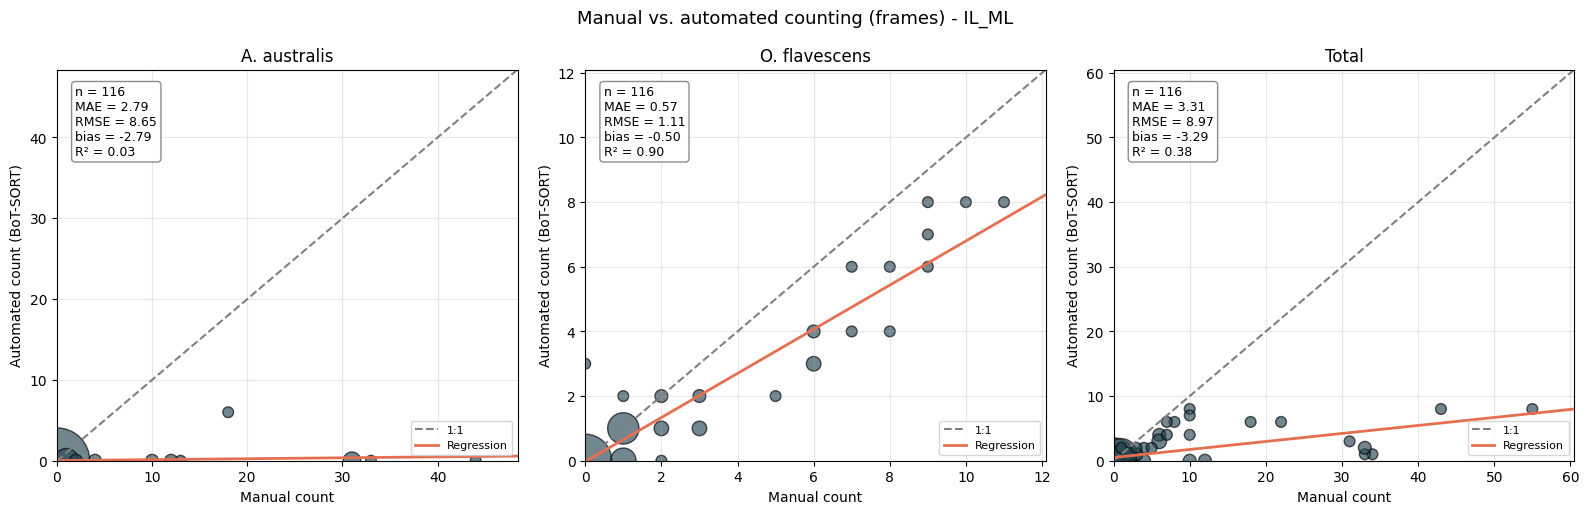


📊 MANUAL vs. AUTOMATED COUNTING - IL_ML (error = automated − manual)
analysis  level         group   n   MAE   RMSE   bias  relative_error_pct  slope  intercept    R2
   IL_ML  clips  A. australis  12 8.333 15.817 -8.333             -92.593  0.029      0.405 0.055
   IL_ML  clips O. flavescens  12 3.500  5.583  3.500              72.414  1.662      0.298 0.869
   IL_ML  clips         Total  12 8.667 13.317 -4.833             -34.940  0.289      5.001 0.265
   IL_ML frames  A. australis 116 2.793  8.651 -2.793             -98.182  0.011      0.019 0.029
   IL_ML frames O. flavescens 116 0.569  1.114 -0.500             -33.721  0.683     -0.030 0.895
   IL_ML frames         Total 116 3.310  8.966 -3.293             -76.096  0.124      0.498 0.381
📁 Files saved to: /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/count_analysis/IL_ML



In [ ]:
# ======================================================
# 18. Manual vs Automated Counting: MAE, RMSE, Bias, and Regression (R²)
#     Three analyses with the SAME single model: REVIS IL, REVIS ML and both areas combined.
# ======================================================
from scipy import stats

ANALYSE_FRAMES = True            # Also compare counts per sampled frame (frame-level spreadsheet)
SPECIES = ['A_AUSTRALIS', 'O_FLAVESCENS']
NAMES = {'A_AUSTRALIS': 'A. australis', 'O_FLAVESCENS': 'O. flavescens', 'TOTAL': 'Total'}

ANALISES = {
    'IL':    [OUT_ROOTS['IL']],
    'ML':    [OUT_ROOTS['ML']],
    'IL_ML': [OUT_ROOTS['IL'], OUT_ROOTS['ML']],     # combined
}


def compute_metrics(h, a):
    """h = manual count (ground truth reference); a = automated count."""
    h, a = np.asarray(h, float), np.asarray(a, float)
    e = a - h
    r = {
        'n': len(h),
        'MAE': np.abs(e).mean(),
        'RMSE': np.sqrt((e ** 2).mean()),
        'bias': e.mean(),
        'relative_error_pct': 100 * e.sum() / h.sum() if h.sum() > 0 else np.nan,
        'slope': np.nan,
        'intercept': np.nan,
        'R2': np.nan
    }
    if len(h) >= 3 and np.ptp(h) > 0:
        lr = stats.linregress(h, a)
        r.update(slope=lr.slope, intercept=lr.intercept, R2=lr.rvalue ** 2)
    return r


def plot_scatter(ax, h, a, title):
    """Plots a 1:1 agreement and linear regression scatter plot."""
    h, a = np.asarray(h, float), np.asarray(a, float)
    counts = collections.Counter(zip(h, a))                    # Overlapping points are scaled larger
    xs, ys = zip(*counts.keys())
    ax.scatter(xs, ys, s=[35 + 25 * v for v in counts.values()], alpha=0.65, color='#264653', edgecolor='k')
    lim = max(h.max(), a.max(), 1) * 1.1
    ax.plot([0, lim], [0, lim], '--', color='gray', label='1:1')
    m = compute_metrics(h, a)
    if not np.isnan(m['R2']):
        xx = np.array([0, lim])
        ax.plot(xx, m['intercept'] + m['slope'] * xx, color='#e76f51', lw=2, label='Regression')
    txt = f"n = {m['n']}\nMAE = {m['MAE']:.2f}\nRMSE = {m['RMSE']:.2f}\nbias = {m['bias']:+.2f}"
    if not np.isnan(m['R2']):
        txt += f"\nR² = {m['R2']:.2f}"
    ax.text(0.04, 0.96, txt, transform=ax.transAxes, va='top', fontsize=9,
            bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.9))
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel('Manual count'); ax.set_ylabel('Automated count (BoT-SORT)')
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=8)


def summarise_level(df, prefix_h, prefix_a, level, out_an, label):
    """Computes metrics and generates scatter plots for A. australis, O. flavescens, and total counts."""
    rows = []
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
    for ax, k in zip(axes, SPECIES + ['TOTAL']):
        h, a = df[f'{prefix_h}{k}'], df[f'{prefix_a}{k}']
        rows.append({'level': level, 'group': NAMES[k], **compute_metrics(h, a)})
        plot_scatter(ax, h, a, NAMES[k])
    fig.suptitle(f'Manual vs. automated counting ({level}) - {label}', fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(out_an, f'scatter_{level}.png'), dpi=300, bbox_inches='tight')
    plt.show()
    return pd.DataFrame(rows)


def analisar(nome, folders):
    out_an = os.path.join(BOTSORT_DIR, 'count_analysis', nome)
    os.makedirs(out_an, exist_ok=True)

    folders = [p for p in folders
               if os.path.exists(os.path.join(p, 'automated_counts.csv'))
               and os.path.exists(os.path.join(p, 'manual_count_clips.csv'))]
    if not folders:
        print(f"⚠️ [{nome}] automated/manual count files not found; analysis skipped")
        return None

    # A) Clip-level: number of distinct individuals (valid tracks) vs manual clip count
    auto = pd.concat([read_csv_auto(os.path.join(p, 'automated_counts.csv')).assign(folder=p) for p in folders],
                     ignore_index=True)
    hum = pd.concat([read_csv_auto(os.path.join(p, 'manual_count_clips.csv')).assign(folder=p) for p in folders],
                    ignore_index=True)
    for k in SPECIES:
        hum[k] = pd.to_numeric(hum[k], errors='coerce')

    pending = hum[hum[SPECIES].isna().any(axis=1)]['clip'].tolist()
    if pending:
        print(f"⚠️ [{nome}] {len(pending)} clip(s) missing complete manual counts (skipped): {pending}")
    hum = hum.dropna(subset=SPECIES)

    c = auto.merge(hum[['folder', 'clip'] + SPECIES], on=['folder', 'clip'], suffixes=('_auto', '_man'))
    if len(c) == 0:
        print(f"⚠️ [{nome}] No clips with both manual and automated counts; analysis skipped")
        return None

    c['total_man'] = c['A_AUSTRALIS_man'] + c['O_FLAVESCENS_man']
    c['total_auto'] = c['A_AUSTRALIS_auto'] + c['O_FLAVESCENS_auto']
    c = c.rename(columns={
        'A_AUSTRALIS_man': 'man_A_AUSTRALIS', 'O_FLAVESCENS_man': 'man_O_FLAVESCENS', 'total_man': 'man_TOTAL',
        'A_AUSTRALIS_auto': 'auto_A_AUSTRALIS', 'O_FLAVESCENS_auto': 'auto_O_FLAVESCENS', 'total_auto': 'auto_TOTAL'
    })
    for k in SPECIES + ['TOTAL']:
        c[f'error_{k}'] = c[f'auto_{k}'] - c[f'man_{k}']

    cols = ['clip'] + [f'{t}_{k}' for k in SPECIES + ['TOTAL'] for t in ('man', 'auto', 'error')]
    c[cols].to_csv(os.path.join(out_an, 'comparison_per_clip.csv'), sep=';', index=False, encoding='utf-8-sig')
    res_clips = summarise_level(c, 'man_', 'auto_', 'clips', out_an, nome)

    if len(c) < 3:
        print(f"ℹ️ [{nome}] Fewer than 3 clips: linear regression and R² are not computed.")
    elif len(c) < 5:
        print(f"ℹ️ [{nome}] Few clips (less than 5): interpret linear regression and R² with caution.")

    # B) Sampled frame-level: number of visible animals in frame (valid tracks) vs manual frame count
    res_frames = pd.DataFrame()
    if ANALYSE_FRAMES:
        paths_q = [p for p in folders if os.path.exists(os.path.join(p, 'manual_count_frames.csv'))]
        if paths_q:
            hq = pd.concat([read_csv_auto(os.path.join(p, 'manual_count_frames.csv')).assign(folder=p) for p in paths_q],
                           ignore_index=True)
            for k in SPECIES:
                hq[k] = pd.to_numeric(hq[k], errors='coerce')
            hq = hq.dropna(subset=SPECIES)
            hq = hq.merge(c[['folder', 'clip']].drop_duplicates(), on=['folder', 'clip'])   # only analysed clips

            parts = []
            for (folder, clip), g in hq.groupby(['folder', 'clip']):
                d = os.path.join(folder, os.path.splitext(clip)[0].replace(' ', '_'))
                f_det, f_tr = os.path.join(d, 'detections_with_id.csv'), os.path.join(d, 'trajectories.csv')
                cont = pd.DataFrame(0, index=g['frame'].values, columns=[0, 1])
                if os.path.exists(f_det) and os.path.exists(f_tr) and os.path.getsize(f_tr) > 5:
                    det, tr = pd.read_csv(f_det), pd.read_csv(f_tr)
                    ok = tr[(tr['n_frames'] >= MIN_LEN) & (tr['mean_conf'] >= MIN_CONF)][['id', 'species_class']]
                    det = det.merge(ok, on='id')
                    n_q = (det.groupby(['frame', 'species_class'])['id'].nunique()
                              .unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0))
                    cont = n_q.reindex(g['frame'].values, fill_value=0)
                g = g.copy()
                g['auto_A_AUSTRALIS'] = cont[0].values
                g['auto_O_FLAVESCENS'] = cont[1].values
                parts.append(g)

            if parts:
                q = pd.concat(parts, ignore_index=True)
                q = q.rename(columns={'A_AUSTRALIS': 'man_A_AUSTRALIS', 'O_FLAVESCENS': 'man_O_FLAVESCENS'})
                q['man_TOTAL'] = q['man_A_AUSTRALIS'] + q['man_O_FLAVESCENS']
                q['auto_TOTAL'] = q['auto_A_AUSTRALIS'] + q['auto_O_FLAVESCENS']
                q.drop(columns='folder').to_csv(os.path.join(out_an, 'comparison_per_frame.csv'),
                                                sep=';', index=False, encoding='utf-8-sig')
                res_frames = summarise_level(q, 'man_', 'auto_', 'frames', out_an, nome)
            else:
                print(f"ℹ️ [{nome}] No frames with manual counts; frame-level analysis skipped")

    res = pd.concat([res_clips, res_frames], ignore_index=True)
    res.insert(0, 'analysis', nome)
    res.to_csv(os.path.join(out_an, 'counting_metrics.csv'), sep=';', index=False, encoding='utf-8-sig', decimal=',')

    print("\n" + "=" * 78)
    print(f"📊 MANUAL vs. AUTOMATED COUNTING - {nome} (error = automated − manual)")
    print("=" * 78)
    print(res.round(3).to_string(index=False))
    print(f"📁 Files saved to: {out_an}\n")
    return res


todas = [r for r in (analisar(n, f) for n, f in ANALISES.items()) if r is not None]
if todas:
    pd.concat(todas, ignore_index=True).to_csv(
        os.path.join(BOTSORT_DIR, 'count_analysis', 'counting_metrics_all_analyses.csv'),
        sep=';', index=False, encoding='utf-8-sig', decimal=',')

In [ ]:
# ======================================================
# 19. Real-Time Species Counter Video Overlay (single model, both areas - from the detections saved in cell 16)
#     Each individual is assigned a sequential per-species ID (A1, A2... / O1, O2...),
#     ordered by entry into the counter. Bounding boxes appear only from the frame
#     in which the individual is counted, ensuring the final species label always
#     matches the cumulative count displayed on the overlay panel.
# ======================================================
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

# MIN_LEN and MIN_CONF are inherited from cell 14
OUTPUT_HEIGHT = 1080       # Output video height in pixels (None = native resolution; 4K videos are large)
RENDER_SE_NAO_EXISTE = True   # Skip clips whose overlay video already exists
COLOURS = {0: (255, 170, 0), 1: (0, 140, 255)}        # BGR: A. australis = light blue | O. flavescens = orange
SPECIES_NAMES = {0: 'A. australis', 1: 'O. flavescens'}
SPECIES_PREFIX = {0: 'A', 1: 'O'}

ITALIC_FONT = font_manager.findfont(
    font_manager.FontProperties(family='DejaVu Sans', style='italic'),
    fallback_to_default=False
)  # DejaVu Sans Oblique (bundled with Matplotlib)


def draw_italic_text(img, text, org, colour_bgr, height_px):
    """Renders italicised text (baseline anchored at org) in-place onto a BGR image array."""
    fnt = ImageFont.truetype(ITALIC_FONT, max(10, height_px))
    x, y = org
    l, t, r, b = fnt.getbbox(text, anchor='ls')
    x0, y0 = max(0, x + l - 3), max(0, y + t - 3)
    x1, y1 = min(img.shape[1], x + r + 3), min(img.shape[0], y + b + 3)
    if x1 <= x0 or y1 <= y0:
        return
    patch = Image.fromarray(cv2.cvtColor(img[y0:y1, x0:x1], cv2.COLOR_BGR2RGB))
    ImageDraw.Draw(patch).text((x - x0, y - y0), text, font=fnt,
                               fill=(colour_bgr[2], colour_bgr[1], colour_bgr[0]), anchor='ls')
    img[y0:y1, x0:x1] = cv2.cvtColor(np.array(patch), cv2.COLOR_RGB2BGR)


def render_counter_video(clip, out_dir, output_path):
    """Generates an H.264 video overlaid with validated bounding boxes and a real-time species counter."""
    d_det = os.path.join(out_dir, 'detections_with_id.csv')
    d_tr = os.path.join(out_dir, 'trajectories.csv')
    cap = cv2.VideoCapture(clip)
    fps = cap.get(cv2.CAP_PROP_FPS)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    n_fr = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    scale = 1.0 if not OUTPUT_HEIGHT else OUTPUT_HEIGHT / H
    W2, H2 = int(round(W * scale)) // 2 * 2, int(round(H * scale)) // 2 * 2   # Even dimensions (required by H.264)

    # ---- Validated trajectories (identical filtering criteria to counting) ----
    if os.path.exists(d_tr) and os.path.getsize(d_tr) > 5:
        tr = pd.read_csv(d_tr)
        ok = tr[(tr['n_frames'] >= MIN_LEN) & (tr['mean_conf'] >= MIN_CONF)][['id', 'species_class']]
        det = pd.read_csv(d_det).merge(ok, on='id')
    else:
        det = pd.DataFrame(columns=['frame', 'id', 'conf', 'cls', 'x1', 'y1', 'x2', 'y2', 'species_class'])
    det = det.sort_values(['id', 'frame'])

    # ---- Individual enters the counter on the frame its trajectory reaches MIN_LEN detections ----
    cum_counts = np.zeros((2, n_fr + 1), int)
    track_labels = {}                            # Track ID -> sequential label (A1, A2, ..., O1, O2, ...)
    if len(det):
        f_count = det.groupby('id').agg(
            f=('frame', lambda s: s.iloc[MIN_LEN - 1]),
            sp=('species_class', 'first')
        )
        order = f_count.sort_values('f', kind='stable')
        for sp in (0, 1):
            ids_sp = order.index[order['sp'] == sp]
            for n, idx in enumerate(ids_sp, 1):
                track_labels[idx] = f"{SPECIES_PREFIX[sp]}{n}"
            fr = order.loc[ids_sp, 'f'].astype(int).values
            fr = fr[fr <= n_fr]
            cum_counts[sp] = np.cumsum(np.bincount(fr, minlength=n_fr + 1)[:n_fr + 1])

        # Draw bounding box only from the frame the individual is counted onwards
        det = det.merge(f_count['f'].rename('f_count'), left_on='id', right_index=True)
        det = det[det['frame'] >= det['f_count']]
    by_frame = {f: g for f, g in det.groupby('frame')}

    tmp = output_path.replace('.mp4', '_tmp.mp4')
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W2, H2))
    font, k = cv2.FONT_HERSHEY_SIMPLEX, H2 / 1080
    i = 0
    while True:
        ok_, frame = cap.read()
        if not ok_:
            break
        frame = cv2.resize(frame, (W2, H2))
        g = by_frame.get(i)
        if g is not None:
            for _, r in g.iterrows():
                sp = int(r['species_class'])
                p1 = (int(r['x1'] * W2 / W), int(r['y1'] * H2 / H))
                p2 = (int(r['x2'] * W2 / W), int(r['y2'] * H2 / H))
                cv2.rectangle(frame, p1, p2, COLOURS[sp], max(2, int(3 * k)))
                draw_italic_text(frame, SPECIES_NAMES[sp],
                                 (p1[0], max(int(24 * k), p1[1] - int(8 * k))), COLOURS[sp], int(26 * k))

        # Translucent counter overlay panel
        px, py, pw, ph = int(20 * k), int(20 * k), int(520 * k), int(160 * k)
        overlay = frame.copy()
        cv2.rectangle(overlay, (px, py), (px + pw, py + ph), (0, 0, 0), -1)
        frame = cv2.addWeighted(overlay, 0.55, frame, 0.45, 0)
        cv2.putText(frame, 'Counted individuals', (px + int(15 * k), py + int(35 * k)),
                    font, 0.8 * k, (255, 255, 255), max(1, int(2 * k)), cv2.LINE_AA)
        for j, sp in enumerate((0, 1)):
            y = py + int((85 + 50 * j) * k)
            cv2.rectangle(frame, (px + int(15 * k), y - int(24 * k)), (px + int(39 * k), y), COLOURS[sp], -1)
            cv2.putText(frame, f"{SPECIES_NAMES[sp]}: {cum_counts[sp][min(i, n_fr)]}",
                        (px + int(55 * k), y), font, 0.95 * k, COLOURS[sp], max(2, int(2 * k)), cv2.LINE_AA)

        vw.write(frame)
        i += 1
    cap.release()
    vw.release()

    # Re-encode to H.264 (ensures playback compatibility across browsers, Colab, and media players)
    subprocess.run(
        ['ffmpeg', '-y', '-loglevel', 'error', '-i', tmp, '-c:v', 'libx264', '-preset', 'veryfast',
         '-crf', '20', '-pix_fmt', 'yuv420p', output_path],
        check=True
    )
    os.remove(tmp)
    return int(cum_counts[0][-1]), int(cum_counts[1][-1])


for area in AREAS:
    OUT_ROOT, CLIPS_DIR = OUT_ROOTS[area], CLIPS_DIRS[area]
    f_auto = os.path.join(OUT_ROOT, 'automated_counts.csv')
    if not os.path.exists(f_auto):
        print(f"⚠️ [{area}] automated_counts.csv not found (run cell 16 first); skipped")
        continue
    auto = pd.read_csv(f_auto, sep=';', encoding='utf-8-sig')

    for clip in listar_clips(CLIPS_DIR):
        name = os.path.basename(clip)
        if name not in set(auto['clip']):
            continue
        stem = os.path.splitext(name)[0].replace(' ', '_')
        out_dir = os.path.join(OUT_ROOT, stem)
        output_path = os.path.join(out_dir, f'counter_{stem}.mp4')
        if RENDER_SE_NAO_EXISTE and os.path.exists(output_path):
            print(f"⏭️ [{area}] {name}: overlay already exists, skipped")
            continue
        a, o = render_counter_video(clip, out_dir, output_path)
        ref = auto[auto['clip'] == name].iloc[0]
        status = '✅' if (a, o) == (int(ref['A_AUSTRALIS']), int(ref['O_FLAVESCENS'])) else '⚠️ differs from summary table'
        print(f"🎬 [{area}] {name}: final counter A. australis={a} | O. flavescens={o} {status}")
        print(f"   {output_path}")

🎬 [IL] DJI_20261113085548_0001_V_clipe01.mp4: final counter A. australis=0 | O. flavescens=0 ✅
   /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/DJI_20261113085548_0001_V_clipe01/counter_DJI_20261113085548_0001_V_clipe01.mp4
🎬 [IL] DJI_20261113085548_0001_V_clipe02.mp4: final counter A. australis=2 | O. flavescens=11 ✅
   /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/DJI_20261113085548_0001_V_clipe02/counter_DJI_20261113085548_0001_V_clipe02.mp4
🎬 [IL] DJI_20261113085548_0001_V_clipe03.mp4: final counter A. australis=0 | O. flavescens=19 ✅
   /content/drive/MyDrive/Colab Notebooks/YOLO_IL_Negativo_ML/YOLO_v26_Negativo/Resultados_Modelo_Unico_IL_ML/BoT-SORT/Results_IL/DJI_20261113085548_0001_V_clipe03/counter_DJI_20261113085548_0001_V_clipe03.mp4
🎬 [IL] DJI_20261113085548_0001_V_clipe04.mp4: final counter A. australis=0 | O. fla